# Public Policy Project 

## Workplace parking pricing and commuting mode

### By Nina Rindisbacher, Florian Loubies, Maxime Sheikhossen and Max Laurent

#### Under the supervision of Pr. Michaël Aklin

---
## 1. Context

A Swiss public employer operates two sites: a **main site in Lausanne (VD)**, and a **secondary site in Sion (VS)**.

Both sites charged staff **CHF 2 per day** for on-site parking in 2024. In 2025, the Lausanne fee increased to **CHF 4**, while the Sion fee **remained CHF 2**. No other mobility policy changed at either site.

All 1,000 employees were surveyed in both years. The employer must now choose its **2026 parking tariff**. Our group acts as a policy-analysis team advising both the **mobility manager** and the **staff council**.

The analysis is guided by three linked questions:
1. How many people stop driving when the price doubles?
2. What would happen at CHF 6 or CHF 8?
3. Who ends up paying?

**Objective:** build a transparent empirical argument from raw data to a defensible policy recommendation.

---
## 2. Data file

`parking_data.csv` contains 2,000 rows: 1,000 employees observed in 2024 and 2025.

| Variable | Type | Description |
|---|---|---|
| `employee_id` | string | Anonymised identifier, stable across years |
| `site` | string | Lausanne or Sion |
| `year` | int | 2024 or 2025 |
| `parking_fee_chf` | float | Daily fee in force at that site and in that year |
| `main_mode` | string | car, bus, or bike |
| `uses_car` | int | 1 if `main_mode == "car"`; 0 otherwise |
| `car_days_per_week` | float | Average days driven to work, from 0 to 5; 0 for non-car commuters |
| `home_commune` | string | Municipality of residence |
| `home_postcode` | int | Swiss postcode |
| `distance_km` | float | Road distance from home to the work site |
| `age` | int | Age |
| `gender` | string | F or M |
| `n_children` | int | Children under 16 in the household: 0, 1, or 2 (2 means "2 or more") |
| `fte` | float | Full-time equivalent contractual workload: 0.6, 0.8, or 1.0 |
| `gross_income_chf` | int | Annual gross income at the employee's observed workload |

**Assumption:** 46 working weeks per year.

> **Note:** The data contain deliberate complications. They must be identified and handled transparently (see the data-cleaning section).

---
## 3. Basic empirical framework

### 3.1 Two margins of car use
1. **Extensive margin:** whether the employee's main commuting mode is car (mode choice).
2. **Intensive margin:** how many days per week a car user drives (frequency).

### 3.2 Equation (1): mode choice (linear probability model)

$$\text{uses\_car} = a \cdot \log(\text{fee}) + \text{controls} + \log(\text{fee}) \times \text{interactions} \tag{1}$$

- Effects are reported in **probability units / percentage points**.
- Interactions: **transit index** (Part A), **income**, and **number of children**.
- The policy can be represented either through $\log(\text{fee})$ or through the **Lausanne × 2025** interaction ($L_i \times \text{Post}_t$) in a site-and-year comparison model. With the same sample, controls and interactions, these are equivalent parameterisations of the same policy variation, but the coefficients have different units.

### 3.3 Equation (2): frequency (car users only)

$$\log(\text{car\_days\_week}) = b \cdot \log(\text{fee}) + \text{controls} + \log(\text{fee}) \times \text{interactions} \tag{2}$$

- Because both the outcome and the fee are logged, $b$ is **directly an elasticity**.
- Interactions: **transit index** (Part A), **income**, and **number of children**.

---
# Part A: Public-transport accessibility by commune

**Goal:** for each home commune, measure how realistic public transport (PT) is as an alternative to the car for arriving at work around 08:00.

**Input:** `parking_data.csv`
**Outputs:**
- `transit_access.csv` (one row per commune)
- Table A1

**Sources:**
- transport.opendata.ch (official SBB timetables)
- api3.geo.admin.ch (swisstopo: communes and the federal Buildings and Dwellings Register, RegBL)
- Google Maps (car travel times)

Run the cells in order (*Run All*).

## A.0 Libraries

In [40]:
import json, math, os, re, time, unicodedata
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timedelta
from threading import RLock

import numpy as np
import pandas as pd
import requests

## A.0b Parameters

All methodological choices are set in the cell below.

**Timetable**
- **Reference date:** Thursday 10 Dec 2026, the last working day of the 2026 timetable (SBB/CFF annual timetable change on 13 Dec 2026). The API does not provide past timetables (2024–2025).
- **Destination:** the main railway station of the site (Lausanne or Sion), since the exact addresses of the sites are not known.
- **Excluded services:** lines that appeared after the 2024–2025 survey (line 9 extended to Crissier, line 54 extended to Epalinges, tram T1). Source: tl (Transports publics de la région lausannoise).

**Choice of the departure stop for each commune**
1. *Dwellings:* all residential buildings of the commune (federal register RegBL), each weighted by its number of dwellings.
2. *Candidate stops:* stops close to the mean dwelling location and to the centre of each quarter of the commune (so that a station on the edge is not missed), plus the commune's main stop (`MAIN_STOP`). Only stops with at least one departure between 06:00 and 09:00 are kept.
3. *Mean total time* of each stop = average walk from all dwellings to the stop + fastest PT trip from the stop to the site's station, arriving between 07:30 and 08:00.
4. *Selected stop:* the one with the lowest mean total time. If several stops are within `TIE_MIN` = 1 minute of this minimum (the timetable is accurate to the minute), keep the one with the shortest average walk.

**Walking and car**
- **Walking:** straight-line distance × `WALK_DETOUR` = 1.3 (street detour), at `WALK_M_PER_MIN` = 75 m/min (4.5 km/h).
- **Car:** Google Maps time (`CAR_TIMES`, from the mean dwelling location to the station, arriving 08:00 on a Thursday). We take the middle of the displayed range and add `CAR_TERMINAL_MIN` = 5 min to park and walk to the site.

In [41]:
REF_DATE = "2026-12-10"     # Thursday, last working day of the 2026 timetable before the
                            # 13.12.2026 change (no tram T1 yet)
WALK_DETOUR = 1.3           # walking path = 1.3 x straight-line distance
WALK_M_PER_MIN = 75         # 4.5 km/h
CAR_TERMINAL_MIN = 5        # parking + walking to the site
TIE_MIN = 1.0               # stops within 1 min of each other = tie -> shortest walk

SITE_STOP = {"Lausanne": "Lausanne", "Sion": "Sion"}           # destination = main station
SITE_COORD = {"Lausanne": (46.5167, 6.6291), "Sion": (46.2274, 7.3592)}

# Main stop of each locality (always added to the candidate stops)
MAIN_STOP = {
    "BOTTENS": "Bottens VD", "BUSSIGNY": "Bussigny", "CHAVANNES PRES RENENS": "Chavannes-près-Renens",
    "CHESEAUX SUR LAUSANNE": "Cheseaux", "CORCELLES LE JORAT": "Corcelles-le-Jorat",
    "CRISSIER": "Crissier, centre", "CUGY": "Cugy VD", "ECUBLENS": "Ecublens VD",
    "EPALINGES": "Epalinges, Croisettes", "FROIDEVILLE": "Froideville", "LAUSANNE": "Lausanne, Chauderon",
    "LE MONT SUR LAUSANNE": "Le Mont-sur-Lausanne", "LUTRY": "Lutry", "MEZIERES": "Mézières VD",
    "MONTPREVEYRES": "Montpreveyres", "MORGES": "Morges", "PRILLY": "Prilly", "PULLY": "Pully",
    "RENENS": "Renens VD", "ROMANEL SUR LAUSANNE": "Romanel-sur-Lausanne", "ROPRAZ": "Ropraz",
    "SAVIGNY": "Savigny VD", "SERVION": "Servion", "VULLIENS": "Vulliens", "ARBAZ": "Arbaz",
    "ARDON": "Ardon", "AYENT": "Ayent", "BRAMOIS": "Bramois", "CONTHEY": "Conthey",
    "EVOLENE": "Evolène", "GRIMISUAT": "Grimisuat", "HEREMENCE": "Hérémence", "NENDAZ": "Basse-Nendaz",
    "SAINT MARTIN": "Saint-Martin VS", "SALINS": "Salins VS", "SAVIESE": "Savièse",
    "SION": "Sion, Platta", "VETROZ": "Vétroz", "VEX": "Vex",
}
NPA_ONLY = {"LAUSANNE", "BRAMOIS", "SALINS"}  # dwellings selected by postcode (neighbourhood / former village)

# Services introduced AFTER the 2024-2025 survey -> excluded (source: tl, Transports publics de la région lausannoise)
#   line 9 extended to Renens/Crissier (08.2026), line 54 (12.2025), tram T1
NEW_SERVICES = {("B", "9"): ["Crissier", "Renens"], ("B", "54"): None,
                ("T", "1"): None, ("T", "T1"): None}

# Google Maps car times (min), from the mean dwelling location to the site's station,
# arriving 08:00 on a Thursday: (lower, upper) bound of the displayed range
CAR_TIMES = {
    "ARBAZ": (20, 30), "ARDON": (14, 22), "AYENT": (20, 20), "BOTTENS": (24, 45), "BRAMOIS": (9, 12),
    "BUSSIGNY": (14, 24), "CHAVANNES PRES RENENS": (12, 20), "CHESEAUX SUR LAUSANNE": (18, 35),
    "CONTHEY": (8, 14), "CORCELLES LE JORAT": (26, 50), "CRISSIER": (16, 28), "CUGY": (22, 40),
    "ECUBLENS": (14, 24), "EPALINGES": (14, 35), "EVOLENE": (35, 35), "FROIDEVILLE": (24, 45),
    "GRIMISUAT": (12, 20), "HEREMENCE": (22, 30), "LAUSANNE": (8, 16), "LE MONT SUR LAUSANNE": (14, 28),
    "LUTRY": (12, 22), "MEZIERES": (26, 45), "MONTPREVEYRES": (24, 45), "MORGES": (16, 24),
    "NENDAZ": (26, 30), "PRILLY": (9, 16), "PULLY": (7, 16), "RENENS": (12, 22),
    "ROMANEL SUR LAUSANNE": (12, 24), "ROPRAZ": (26, 50), "SAINT MARTIN": (31, 31), "SALINS": (14, 14),
    "SAVIESE": (16, 24), "SAVIGNY": (18, 35), "SERVION": (26, 45), "SION": (4, 4), "VETROZ": (12, 18),
    "VEX": (14, 18), "VULLIENS": (30, 55),
}

## A.1 Raw data: inspection and cleaning

We first look at the data as provided (A.1a to A.1e) to spot missing data, impossible values and inconsistencies. We then correct the communes (A.1f) and the remaining issues (A.1g), and aggregate by commune (A.1h). The file `parking_data.csv` itself is never modified.

### A.1a Overview

In [42]:
raw = pd.read_csv("parking_data.csv")
print(raw.shape)
print("Employees:", raw["employee_id"].nunique(), "| years:", sorted(raw["year"].unique()))
print("Rows per employee:", raw.groupby("employee_id").size().value_counts().to_dict())
print("Employees per site:", raw.drop_duplicates("employee_id")["site"].value_counts().to_dict())
raw.head()

(2000, 15)
Employees: 1000 | years: [np.int64(2024), np.int64(2025)]
Rows per employee: {2: 1000}
Employees per site: {'Lausanne': 800, 'Sion': 200}


,employee_id,site,year,parking_fee_chf,main_mode,uses_car,car_days_per_week,home_commune,home_postcode,distance_km,age,gender,n_children,fte,gross_income_chf
0,E1000,Lausanne,2024,2.0,car,1,2.2,Lausanne,1004,2.9,23,M,0,0.8,59300.0
1,E1000,Lausanne,2025,4.0,car,1,2.0,Lausanne,1004,2.9,23,M,0,0.8,59300.0
2,E1001,Lausanne,2024,2.0,car,1,3.5,Le Mont-sur-Lausanne,1052,5.6,51,F,1,1.0,124300.0
3,E1001,Lausanne,2025,4.0,car,1,7.4,Le Mont-sur-Lausanne,1052,5.6,51,F,1,1.0,124300.0
4,E1002,Lausanne,2024,2.0,car,1,2.6,Chavannes-pres-Renens,1022,7.7,39,M,0,1.0,72800.0


### A.1b Missing data and duplicates

In [43]:
print("Missing values per column:")
print(raw.isna().sum()[raw.isna().sum() > 0])
print("\nDuplicates (same employee, same year):", raw.duplicated(["employee_id", "year"]).sum())
miss = raw[raw["gross_income_chf"].isna()]
n_years = miss.groupby("employee_id").size()
print("Missing income:", miss["employee_id"].nunique(), "employees, of which",
      (n_years == 1).sum(), "for one year only and", (n_years == 2).sum(), "for both years")

Missing values per column:
gross_income_chf    110
dtype: int64

Duplicates (same employee, same year): 0
Missing income: 106 employees, of which 102 for one year only and 4 for both years


### A.1c Consistency between 2024 and 2025

These characteristics should not change from one year to the next for a given employee.

In [44]:
for col in ["site", "home_commune", "home_postcode", "distance_km", "age",
            "n_children", "fte", "gross_income_chf"]:
    n = (raw.groupby("employee_id")[col].nunique() > 1).sum()
    print(f"{col:<18} changes for {n} employees")

site               changes for 0 employees
home_commune       changes for 45 employees
home_postcode      changes for 0 employees
distance_km        changes for 0 employees
age                changes for 0 employees
n_children         changes for 0 employees
fte                changes for 0 employees
gross_income_chf   changes for 0 employees


### A.1d Value ranges and logical consistency

We compare the data with the values allowed by the variable descriptions (e.g. `car_days_per_week` between 0 and 5).

In [45]:
print(raw.describe().T[["min", "max", "mean"]])
print("\ncar_days_per_week > 5:")
print(raw.loc[raw["car_days_per_week"] > 5, ["employee_id", "year", "main_mode", "car_days_per_week"]])
print("\nuses_car inconsistent with main_mode:", ((raw["main_mode"] == "car") != (raw["uses_car"] == 1)).sum())
print("Non-car commuters with car days:", ((raw["uses_car"] == 0) & (raw["car_days_per_week"] > 0)).sum())
print("\nModes:", raw["main_mode"].value_counts().to_dict())
print("\nParking fee by site and year:")
print(raw.groupby(["site", "year"])["parking_fee_chf"].unique())

                       min       max          mean
year                2024.0    2025.0   2024.500000
parking_fee_chf        2.0       4.0      2.800000
uses_car               0.0       1.0      0.511000
car_days_per_week      0.0       7.4      1.815650
home_postcode       1004.0    1997.0   1224.999000
distance_km            1.3      37.5      8.343900
age                   22.0      64.0     42.567000
n_children             0.0       2.0      0.748000
fte                    0.6       1.0      0.962600
gross_income_chf   24300.0  222500.0  94784.338624

car_days_per_week > 5:
  employee_id  year main_mode  car_days_per_week
3       E1001  2025       car                7.4

uses_car inconsistent with main_mode: 0
Non-car commuters with car days: 0

Modes: {'car': 1022, 'bus': 705, 'bike': 273}

Parking fee by site and year:
site      year
Lausanne  2024    [2.0]
          2025    [4.0]
Sion      2024    [2.0]
          2025    [2.0]
Name: parking_fee_chf, dtype: object


### A.1e Communes and postcodes

Commune names are written in several ways (accents, hyphens, capitalisation). We harmonise them to see the variants, then check that each commune has only one postcode and that it is the correct one.

In [46]:
def normalize(name):
    """Upper case, no accents or punctuation: 'Chavannes-près-Renens' -> 'CHAVANNES PRES RENENS'."""
    name = unicodedata.normalize("NFKD", str(name).upper().strip())
    name = "".join(ch for ch in name if not unicodedata.combining(ch))
    return re.sub(r"\s+", " ", re.sub(r"[^A-Z0-9]", " ", name)).strip()

check = raw.assign(commune_clean=raw["home_commune"].apply(normalize))
print("Distinct spellings:", raw["home_commune"].nunique(), "-> communes after harmonisation:",
      check["commune_clean"].nunique())
pd.set_option("display.max_rows", 100)
check.groupby("commune_clean").agg(
    site=("site", "unique"),
    variants=("home_commune", lambda s: sorted(s.unique())),
    postcode=("home_postcode", "unique"),
    employees=("employee_id", "nunique"),
)

Distinct spellings: 62 -> communes after harmonisation: 39


,site,variants,postcode,employees
commune_clean,,,,
ARBAZ,[Sion],[Arbaz],[1974],6
ARDON,[Sion],"[ARDON, Ardon]",[1957],11
AYENT,[Sion],"[AYENT, Ayent]",[1966],15
BOTTENS,[Lausanne],"[BOTTENS, Bottens]",[1041],15
BRAMOIS,[Sion],[Bramois],[1967],16
BUSSIGNY,[Lausanne],"[BUSSIGNY, Bussigny]",[1030],43
CHAVANNES PRES RENENS,[Lausanne],"[CHAVANNES PRES RENENS, Chavannes-pres-Renens]",[1022],20
CHESEAUX SUR LAUSANNE,[Lausanne],[Cheseaux-sur-Lausanne],[1033],21
CONTHEY,[Sion],[Conthey],[1964],20


**What the inspection shows:**
- 62 spellings for 39 communes (accents, hyphens, capitalisation) → harmonisation needed.
- **Savièse** is written "Savieze" in all rows (spelling mistake).
- **Salins:** all 8 employees have postcode **1994**, which is the postcode of Aproz (a part of the commune of Nendaz). The postcode of Salins is 1991.
- Each commune has a single postcode. Site, postcode, distance, age, children, FTE and income never change between 2024 and 2025.
- `home_commune` changes between 2024 and 2025 for 45 employees, but **only in spelling** (e.g. "FROIDEVILLE" / "Froideville"). After harmonisation, no employee changes commune (checked in A.1f).
- **Income** is the only variable with missing values (110 rows, 106 employees, 102 of them for one year only).
- **Impossible value:** E1001 reports 7.4 car days per week in 2025 (maximum is 5).
- `uses_car` always matches `main_mode`, and the fees match the project description (Lausanne: CHF 2 → 4; Sion: CHF 2).

### A.1f Correcting the communes

- Names harmonised (`commune_clean`).
- "Savieze" → **SAVIESE**.
- Salins: we trust the commune name → postcode corrected from 1994 to **1991**.

The original values are kept (`commune_clean_raw`, `home_postcode_raw`).

In [47]:
raw["commune_clean"] = raw["home_commune"].apply(normalize)
raw["commune_clean_raw"] = raw["commune_clean"]
raw["home_postcode_raw"] = raw["home_postcode"]

raw["commune_clean"] = raw["commune_clean"].replace({"SAVIEZE": "SAVIESE"})   # spelling mistake
raw.loc[raw["commune_clean"] == "SALINS", "home_postcode"] = 1991              # postcode 1994 = Aproz

print("Communes:", raw["commune_clean"].nunique())
print("Employees changing commune between 2024 and 2025 (after harmonisation):",
      (raw.groupby("employee_id")["commune_clean"].nunique() > 1).sum())
raw.loc[raw["commune_clean"].isin(["SAVIESE", "SALINS"]),
        ["commune_clean_raw", "commune_clean", "home_postcode_raw", "home_postcode"]].drop_duplicates()

Communes: 39
Employees changing commune between 2024 and 2025 (after harmonisation): 0


,commune_clean_raw,commune_clean,home_postcode_raw,home_postcode
1632,SAVIEZE,SAVIESE,1965,1965
1660,SALINS,SALINS,1994,1991


### A.1g Other corrections

- **Income missing for one year only:** we use the value from the other year (income is constant within employee, see A.1c). Employees with no income in either year remain missing. This affects 4 employees (0.4%, i.e. 8 rows). They will have to be excluded from income-based analyses, or imputed with the median of similar profiles (FTE, age, work site).
- **Car days > 5** (impossible): capped at 5.

Original values are kept: `income_imputed` (flag for completed income), `car_days_raw`. These corrections do not affect the Part A results (which only use communes), but they are used in Parts B to E.

In [48]:
raw["income_imputed"] = raw["gross_income_chf"].isna()
raw["gross_income_chf"] = raw.groupby("employee_id")["gross_income_chf"].transform(lambda s: s.fillna(s.mean()))
raw["income_imputed"] &= raw["gross_income_chf"].notna()
print("Incomes completed:", raw["income_imputed"].sum(),
      "| still missing:", raw["gross_income_chf"].isna().sum(), "rows")

raw["car_days_raw"] = raw["car_days_per_week"]
raw["car_days_per_week"] = raw["car_days_per_week"].clip(upper=5)
print("Car days capped at 5:", (raw["car_days_raw"] > 5).sum(), "row(s)")

Incomes completed: 102 | still missing: 8 rows
Car days capped at 5: 1 row(s)


### A.1h One row per commune

In [49]:
communes = (raw.groupby(["commune_clean", "site"])
               .agg(n_employees=("employee_id", "nunique"),
                    postcode=("home_postcode", "first"),
                    mean_distance_km=("distance_km", "mean"))
               .reset_index())
assert len(communes) == 39 and communes.n_employees.sum() == 1000
communes

,commune_clean,site,n_employees,postcode,mean_distance_km
0,ARBAZ,Sion,6,1974,11.483333
1,ARDON,Sion,11,1957,13.809091
2,AYENT,Sion,15,1966,12.773333
3,BOTTENS,Lausanne,15,1041,14.440000
4,BRAMOIS,Sion,16,1967,5.318750
5,BUSSIGNY,Lausanne,43,1030,9.788372
6,CHAVANNES PRES RENENS,Lausanne,20,1022,7.110000
7,CHESEAUX SUR LAUSANNE,Lausanne,21,1033,8.547619
8,CONTHEY,Sion,20,1964,7.225000
9,CORCELLES LE JORAT,Lausanne,13,1082,19.423077


## A.2 API access

Each response is saved in `transit_cache.json`: a request is made only once, and re-running the notebook gives exactly the same results.
Connections that use a service introduced after 2025 are discarded.

In [50]:
CACHE_FILE = "transit_cache.json"
cache = json.load(open(CACHE_FILE)) if os.path.exists(CACHE_FILE) else {}
lock = RLock()


def save_cache():
    with lock:
        with open(CACHE_FILE + ".tmp", "w") as f:
            json.dump(cache, f)
        os.replace(CACHE_FILE + ".tmp", CACHE_FILE)


def get(url, params, transform=None):
    key = url + "?" + json.dumps(params, sort_keys=True)
    if key in cache:
        return cache[key]
    for attempt in range(4):                       # retry if the API is overloaded
        try:
            r = requests.get(url, params=params, timeout=60)
            if r.status_code != 429:
                break
        except requests.ConnectionError:
            pass
        time.sleep(5 * (attempt + 1))
    r.raise_for_status()
    data = transform(r.json()) if transform else r.json()
    with lock:
        cache[key] = data
        if len(cache) % 25 == 0:
            save_cache()
    time.sleep(0.2)
    return data


OPENDATA = "https://transport.opendata.ch/v1/"
GEO = "https://api3.geo.admin.ch/rest/services/api/"


def ts(s):                                         # '2026-12-10T07:52:00+0100' -> datetime
    return datetime.strptime(s[:19], "%Y-%m-%dT%H:%M:%S")


def at(hhmm):                                      # '08:00' -> datetime on the reference day
    return datetime.strptime(f"{REF_DATE} {hhmm}", "%Y-%m-%d %H:%M")


def km(lat1, lon1, lat2, lon2):                    # straight-line (haversine) distance
    p = math.pi / 180
    a = (math.sin((lat2 - lat1) * p / 2) ** 2
         + math.cos(lat1 * p) * math.cos(lat2 * p) * math.sin((lon2 - lon1) * p / 2) ** 2)
    return 12742 * math.asin(math.sqrt(a))


def is_new_service(category, number, boarding_stop):
    prefixes = NEW_SERVICES.get((category, str(number)), False)
    return prefixes is None or (prefixes and any(boarding_stop.startswith(p) for p in prefixes))


def connections(frm, to, hhmm, arrival, limit):
    """PT connections, excluding those that use a service introduced after 2025."""
    res = get(OPENDATA + "connections", {"from": frm, "to": to, "date": REF_DATE, "time": hhmm,
                                         "isArrivalTime": int(arrival), "limit": limit, "page": 0})
    ok = [c for c in res.get("connections", [])
          if not any(s.get("journey") and is_new_service(s["journey"].get("category"),
                                                         s["journey"].get("number"),
                                                         s["departure"]["station"]["name"] or "")
                     for s in c.get("sections", []))]
    return ok, res.get("connections", [])

## A.3 The three PT indicators for a stop

1. **08:00 trip:** the fastest trip arriving between 07:30 and 08:00 (otherwise the last one before 08:00).
2. **Departures 06:00–09:00:** number of distinct departures to the site between 06:00 and 09:00.
3. **First arrival:** time of the first possible morning arrival at the site.

In [51]:
def trip_0800(stop, site):
    """Fastest trip arriving between 07:30 and 08:00 (otherwise the last one before 08:00)."""
    cons, _ = connections(stop, SITE_STOP[site], "08:00", arrival=True, limit=6)
    cons = [c for c in cons if ts(c["to"]["arrival"]) <= at("08:00")]
    pool = ([c for c in cons if ts(c["to"]["arrival"]) >= at("07:30")]
            or sorted(cons, key=lambda c: ts(c["to"]["arrival"]))[-1:])
    if not pool:
        return None
    return min(pool, key=lambda c: ts(c["to"]["arrival"]) - ts(c["from"]["departure"]))


def trip_minutes(c):
    return (ts(c["to"]["arrival"]) - ts(c["from"]["departure"])).total_seconds() / 60


def departures_6_9(stop, site):
    """Distinct departures 06:00-09:00 to the site (the API returns 16 connections per request)."""
    deps, hhmm = set(), "06:00"
    for _ in range(30):
        ok, allc = connections(stop, SITE_STOP[site], hhmm, arrival=False, limit=16)
        if not allc:
            break
        deps |= {ts(c["from"]["departure"]) for c in ok
                 if at("06:00") <= ts(c["from"]["departure"]) < at("09:00")}
        last = max(ts(c["from"]["departure"]) for c in allc)
        nxt = (last + timedelta(minutes=1)).strftime("%H:%M")
        if last >= at("09:00") or nxt <= hhmm:
            break
        hhmm = nxt
    return len(deps)


def first_arrival(stop, site):
    ok, _ = connections(stop, SITE_STOP[site], "04:00", arrival=False, limit=4)
    arr = [ts(c["to"]["arrival"]) for c in ok if ts(c["to"]["arrival"]).date() == at("04:00").date()]
    return min(arr).strftime("%H:%M") if arr else None


def served_6_9(stop_id, stop_name):
    """At least one departure (any direction) between 06:00 and 09:00 at this stop?"""
    r = get(OPENDATA + "stationboard", {"id": stop_id, "datetime": f"{REF_DATE} 06:00", "limit": 200})
    return any(d.get("stop", {}).get("departure")
               and at("06:00") <= ts(d["stop"]["departure"]) < at("09:00")
               and not is_new_service(d.get("category"), d.get("number"), stop_name)
               for d in r.get("stationboard", []))

## A.4 Dwellings and selected stop for a commune

1. **Dwellings:** all residential buildings of the locality (federal register RegBL), weighted by their number of dwellings. For Lausanne, only the employees' postcode (1004) is used.
2. **Candidate stops:** stops close to the mean dwelling location and to the centre of each quarter of the locality, plus the main stop.
3. **Selected stop:** among the stops served between 06:00 and 09:00, the one that minimises **average walk from all dwellings + 08:00 PT trip**. A tie (< 1 min) → shortest walk.

In [52]:
def commune_centre(commune, site, road_km):
    """Centre of the commune (swisstopo). Rejects homonyms that are too far from the site."""
    road_km = max(road_km, 10) if commune == site.upper() else road_km
    for layer in ("gg25", "gazetteer"):            # gg25 = communes ; gazetteer = villages
        r = get(GEO + "SearchServer", {"searchText": commune.title(), "type": "locations",
                                       "origins": layer, "sr": "4326"})
        for res in r.get("results", []):
            a = res["attrs"]
            label = re.sub(r"<[^>]+>", "", a.get("label", ""))
            if commune in normalize(label) and km(a["lat"], a["lon"], *SITE_COORD[site]) <= road_km + 3:
                return a["lat"], a["lon"], a.get("featureId") if layer == "gg25" else None
    return None


def compact(data):                                 # keep only 5 columns of the register
    keep = ("egid", "ganzwhg", "gkat", "gstat", "plz_plz6")
    return {"results": [{"featureId": f.get("featureId"),
                         "attributes": {k: f.get("attributes", {}).get(k) for k in keep},
                         "geometry": {"x": f.get("geometry", {}).get("x"),
                                      "y": f.get("geometry", {}).get("y")}}
                        for f in data.get("results", [])]}


def dwellings(search_value, field):
    """Residential buildings (RegBL): list of (lat, lon, number of dwellings, postcode). ~200 rows per page."""
    rows, seen, offset = [], set(), 0
    while True:
        page = get(GEO + "MapServer/find",
                   {"layer": "ch.bfs.gebaeude_wohnungs_register", "searchText": str(search_value),
                    "searchField": field, "returnGeometry": "true", "sr": "4326",
                    "contains": "false", "offset": offset}, transform=compact)["results"]
        new = [f for f in page if f["featureId"] not in seen]
        if not new:
            break
        seen |= {f["featureId"] for f in new}
        rows += new
        offset += 200
        if len(page) < 200:
            break
    out, buildings = [], set()
    for f in rows:                                 # one row per dwelling -> one per building
        a, g = f["attributes"], f["geometry"]
        if g["x"] is None or a["egid"] in buildings or str(a.get("gstat")) not in ("1004", "None"):
            continue
        buildings.add(a["egid"])
        w = float(a.get("ganzwhg") or 0) or (1 if str(a.get("gkat")) in ("1020", "1030", "1040") else 0)
        if w > 0:
            out.append((g["y"], g["x"], w, str(a.get("plz_plz6", ""))[:4]))
    return out


def stops_near(lat, lon):
    r = get(OPENDATA + "locations", {"x": lat, "y": lon, "type": "station"})
    found = [s for s in r.get("stations", []) if s.get("id") and (s.get("coordinate") or {}).get("x")]
    found.sort(key=lambda s: s.get("distance") or 0)               # nearest to farthest
    return [(s["id"], s["name"], s["coordinate"]["x"], s["coordinate"]["y"]) for s in found]


def wmean(values, weights):
    return sum(v * w for v, w in zip(values, weights)) / sum(weights)


def analyse_commune(commune, site, npa, road_km):
    # --- dwellings of the locality ---
    if commune in NPA_ONLY:                        # buildings of the employees' postcode
        homes = dwellings(npa, "dplz4")            # (Lausanne 1004, Bramois 1967, Salins 1991)
    else:
        centre = commune_centre(commune, site, road_km)
        homes = dwellings(centre[2], "ggdenr")
        same_npa = [h for h in homes if h[3] == str(npa)]
        homes = same_npa if len(same_npa) >= 10 else homes
    lat, lon, w = [h[0] for h in homes], [h[1] for h in homes], [h[2] for h in homes]
    clat, clon = wmean(lat, w), wmean(lon, w)

    # --- candidate stops: around the centre, the centre of each quarter, + main stop ---
    cands = {s[0]: s for s in stops_near(clat, clon)}
    mlat, mlon = sorted(lat)[len(lat) // 2], sorted(lon)[len(lon) // 2]
    for north in (True, False):
        for east in (True, False):
            q = [h for h in homes if (h[0] >= mlat) == north and (h[1] >= mlon) == east]
            if q:
                qlat, qlon = wmean([h[0] for h in q], [h[2] for h in q]), wmean([h[1] for h in q], [h[2] for h in q])
                for s in [s for s in stops_near(qlat, qlon) if s[0] not in cands][:5]:
                    cands[s[0]] = s
        # + stops near the outermost dwellings (N, S, E, W): stations on the commune boundary
    for h in (max(homes, key=lambda h: h[0]), min(homes, key=lambda h: h[0]),
              max(homes, key=lambda h: h[1]), min(homes, key=lambda h: h[1])):
        for s in [s for s in stops_near(h[0], h[1]) if s[0] not in cands][:5]:
            cands[s[0]] = s
    for name in [MAIN_STOP[commune]]:
        found = [(s["id"], s["name"], s["coordinate"]["x"], s["coordinate"]["y"])
                 for s in get(OPENDATA + "locations", {"query": name, "type": "station"}).get("stations", [])
                 if s.get("id") and (s.get("coordinate") or {}).get("x")]
        if found:
            cands.setdefault(found[0][0], found[0])
    cands = list(cands.values())

    # --- served stops and their trip to the site (4 parallel requests) ---
    with ThreadPoolExecutor(4) as ex:
        served = [s for s, ok in zip(cands, ex.map(lambda s: served_6_9(s[0], s[1]), cands)) if ok]
        trips = dict(zip([s[0] for s in served], ex.map(lambda s: trip_0800(s[1], site), served)))
    served = [s for s in served if trips[s[0]]]

    # --- selected stop: lowest (average walk + trip); tie -> shortest walk ---
    def walk(s):
        return wmean([km(h[0], h[1], s[2], s[3]) * 1000 * WALK_DETOUR / WALK_M_PER_MIN for h in homes], w)

    total = {s[0]: walk(s) + trip_minutes(trips[s[0]]) for s in served}
    best = min([s for s in served if total[s[0]] < min(total.values()) + TIE_MIN], key=walk)

    # share of dwellings for which this stop would also be the best individual choice
    def own_best(h):
        return min(served, key=lambda s: km(h[0], h[1], s[2], s[3]) * 1000 * WALK_DETOUR / WALK_M_PER_MIN
                   + trip_minutes(trips[s[0]]))[0]
    share = sum(h[2] for h in homes if own_best(h) == best[0]) / sum(w)

    trip = trips[best[0]]
    return {
        "origin_stop": best[1],
        "n_dwellings": int(sum(w)),
        "share_dwellings_using_stop": round(share, 2),
        "dwellings_centre_latlon": f"{clat:.5f}, {clon:.5f}",
        "walk_to_origin_stop_min": round(walk(best), 1),
        "pt_stop_to_stop_min": trip_minutes(trip),
        "pt_transfers": trip.get("transfers"),
        "pt_total_via_origin_min": round(walk(best) + trip_minutes(trip), 1),
        "n_departures_6_9": departures_6_9(best[1], site),
        "arrival_before_0800": ts(trip["to"]["arrival"]).strftime("%H:%M"),
        "first_arrival": first_arrival(best[1], site),
    }

## A.5 Computation for the 39 communes

The switch `RUN_API` controls the source of the commune-level measure:
- `RUN_API = False` (default): load the precomputed `transit_access.csv`. Instant.
- `RUN_API = True`: recompute everything from the APIs (needs internet; about 15 to 45 minutes on a first run, a few seconds if `transit_cache.json` is present).

The file `transit_access.csv` in the submission was produced with `RUN_API = True`.

In [53]:
RUN_API = False   # True = recompute from the APIs (internet needed); False = load transit_access.csv

### Sanity check: Chavannes-près-Renens

The selected stop for a commune is not always the nearest station. This check shows that Renens station is among the candidate stops for Chavannes-près-Renens, and compares it directly with the stop that was selected (Concorde). The two options are close in total time: Concorde (average walk 9.6 min + trip 12 min = 21.6 min) and Renens station (15.8 + 5 = 20.8 min). Renens is 0.8 min faster, which is below the 1-minute tie threshold, so the stop with the shortest walk (Concorde) is retained.

In [54]:
if RUN_API:
    # Chavannes: is Renens station a candidate, and how does it compare with Concorde?
    commune, site = "CHAVANNES PRES RENENS", "Lausanne"
    r = communes[communes.commune_clean == commune].iloc[0]
    centre = commune_centre(commune, site, r.mean_distance_km)
    homes = [h for h in dwellings(centre[2], "ggdenr") if h[3] == str(r.postcode)]
    w = [h[2] for h in homes]

    edge = set()
    for h in (max(homes, key=lambda h: h[0]), min(homes, key=lambda h: h[0]),
              max(homes, key=lambda h: h[1]), min(homes, key=lambda h: h[1])):
        edge |= {s[1] for s in stops_near(h[0], h[1])[:5]}
    print("Renens station found via the edge dwellings:", "Renens VD" in edge)

    for name in ["Chavannes-R., Concorde", "Renens VD"]:
        s = get(OPENDATA + "locations", {"query": name, "type": "station"})["stations"][0]
        walking = wmean([km(h[0], h[1], s["coordinate"]["x"], s["coordinate"]["y"]) * 1000
                         * WALK_DETOUR / WALK_M_PER_MIN for h in homes], w)
        trip_time = trip_minutes(trip_0800(s["name"], site))
        print(f"{s['name']:<25} walk {walking:5.1f} + trip {trip_time:4.0f} = {walking + trip_time:5.1f} min")
else:
    print("Skipped (RUN_API = False): this check queries the live APIs.")

Skipped (RUN_API = False): this check queries the live APIs.


### For the 39 communes

In [55]:
if RUN_API:
    rows = []
    try:
        for i, r in communes.iterrows():
            print(f"[{i + 1}/39] {r.commune_clean}", end=" ", flush=True)
            res = analyse_commune(r.commune_clean, r.site, r.postcode, r.mean_distance_km)
            print(f"-> {res['origin_stop']} ({res['pt_total_via_origin_min']} min)")
            rows.append({**r.to_dict(), **res})
    finally:
        save_cache()
    ta = pd.DataFrame(rows)
else:
    ta = pd.read_csv("transit_access.csv")

ta.head()

,commune_clean,site,n_employees,postcode,origin_stop,n_dwellings,share_dwellings_using_stop,dwellings_centre_latlon,walk_to_origin_stop_min,pt_stop_to_stop_min,...,first_arrival,car_min_low,car_min_high,car_door_mid_min,ratio_pt_car_mid,ratio_pt_car_high,transit_index,transit_group,source,coding_notes
0,ARBAZ,Sion,6,1974,"Arbaz, poste",976,0.23,"46.27759, 7.38421",12.2,28.0,...,06:47,20,30,30.0,1.34,1.15,-1.037,1_low,Timetables: transport.opendata.ch (official SB...,Selected stop = served stop (>=1 departure 06-...
1,ARDON,Sion,11,1957,Ardon,1808,0.47,"46.20972, 7.25950",16.2,7.0,...,04:45,14,22,23.0,1.01,0.86,0.520,3_high,Timetables: transport.opendata.ch (official SB...,Selected stop = served stop (>=1 departure 06-...
2,AYENT,Sion,15,1966,"Botyre (Ayent), Le Creux",1973,0.05,"46.27920, 7.40956",19.0,27.0,...,06:30,20,20,25.0,1.84,1.84,-1.238,1_low,Timetables: transport.opendata.ch (official SB...,Selected stop = served stop (>=1 departure 06-...
3,BOTTENS,Lausanne,15,1041,"Bottens, croisée",607,0.96,"46.61618, 6.66106",6.0,36.0,...,06:04,24,45,39.5,1.06,0.84,-0.042,1_low,Timetables: transport.opendata.ch (official SB...,Selected stop = served stop (>=1 departure 06-...
4,BRAMOIS,Sion,16,1967,"Bramois, La Borgne",2045,0.24,"46.23141, 7.40070",10.9,10.0,...,06:05,9,12,15.5,1.35,1.23,-0.124,3_high,Timetables: transport.opendata.ch (official SB...,Selected stop = served stop (>=1 departure 06-...


### Car time and PT/car ratio

Car time = middle of the Google range + 5 min. Ratio = total PT time (walk + trip) ÷ car time. A ratio < 1 means PT is faster than the car.

In [56]:
# Car time and PT / car ratio
ta["car_min_low"] = ta.commune_clean.map(lambda c: CAR_TIMES[c][0])
ta["car_min_high"] = ta.commune_clean.map(lambda c: CAR_TIMES[c][1])
ta["car_door_mid_min"] = (ta.car_min_low + ta.car_min_high) / 2 + CAR_TERMINAL_MIN
ta["ratio_pt_car_mid"] = (ta.pt_total_via_origin_min / ta.car_door_mid_min).round(2)
ta["ratio_pt_car_high"] = (ta.pt_total_via_origin_min / (ta.car_min_high + CAR_TERMINAL_MIN)).round(2)

ta[["site", "commune_clean", "pt_total_via_origin_min", "car_door_mid_min", "ratio_pt_car_mid"]]

,site,commune_clean,pt_total_via_origin_min,car_door_mid_min,ratio_pt_car_mid
0,Sion,ARBAZ,40.2,30.0,1.34
1,Sion,ARDON,23.2,23.0,1.01
2,Sion,AYENT,46.0,25.0,1.84
3,Lausanne,BOTTENS,42.0,39.5,1.06
4,Sion,BRAMOIS,20.9,15.5,1.35
5,Lausanne,BUSSIGNY,20.6,24.0,0.86
6,Lausanne,CHAVANNES PRES RENENS,21.6,21.0,1.03
7,Lausanne,CHESEAUX SUR LAUSANNE,30.4,31.5,0.97
8,Sion,CONTHEY,21.1,16.0,1.32
9,Lausanne,CORCELLES LE JORAT,55.9,43.0,1.30


## A.6 Index and groups

- **Index:** mean of the 3 standardised indicators (z-scores): −(PT/car ratio), log(1 + departures 06:00–09:00), −(first arrival time). The higher the index, the better the PT access.
- **Groups:** terciles of the index, weighted by number of employees and **computed within each site**, so that every group contains employees from Lausanne (treated) and from Sion (control).

In [57]:
fa = pd.to_datetime(ta.first_arrival, format="%H:%M")
first_min = fa.dt.hour * 60 + fa.dt.minute
z = lambda s: (s - s.mean()) / s.std()
index = lambda ratio: (z(-ratio) + z(np.log1p(ta.n_departures_6_9)) + z(-first_min)) / 3
ta["transit_index"] = index(ta.ratio_pt_car_mid).round(3)       # higher = better PT access


def terciles(g):
    """3 groups of about 1/3 of the employees each, within one site."""
    g = g.sort_values("transit_index")
    position = (g.n_employees.cumsum() - g.n_employees / 2) / g.n_employees.sum()
    return pd.cut(position, [0, 1 / 3, 2 / 3, 1], labels=["1_low", "2_medium", "3_high"]).astype(str)


ta["transit_group"] = pd.concat([terciles(g) for _, g in ta.groupby("site")])

### Export: `transit_access.csv` and Table A1

`transit_access.csv` is only rewritten when `RUN_API = True`, so that the submitted file is never overwritten by a re-run that simply reloads it. Table A1 is displayed below and reported in the next cell.

In [60]:
ta["source"] = (f"Timetables: transport.opendata.ch (official SBB timetables), Thursday {REF_DATE}. "
                "Dwellings: RegBL via api3.geo.admin.ch. Communes: swisstopo. "
                "Car times: Google Maps, arrival 08:00 on a Thursday. "
                "Services introduced after 2025: tl (Transports publics de la région lausannoise).")
ta["coding_notes"] = (
    "Selected stop = served stop (>=1 departure 06-09h) that minimises the average walk from all "
    "RegBL dwellings of the locality (straight line x1.3, 75 m/min, weighted by number of dwellings) + "
    "the fastest PT trip arriving 07:30-08:00; tie (<1 min) -> shortest walk. Candidates: "
    "stops close to the centre and to the centre of each quarter of the locality + main stop. "
    "Lausanne, Bramois, Salins: dwellings selected by the employees' postcode (1004, 1967, 1991). "
    "Destination: main station of the site. Services introduced after 2025 excluded "
    "(line 9 at Renens/Crissier, line 54, tram T1; source: tl). Car: middle of the Google range + 5 min "
    "(parking + walking); ratio_pt_car_high = using the upper bound. "
    "transit_index = mean of the z-scores of (-PT/car ratio, log(1+departures 06-09h), -first "
    "arrival). transit_group = terciles of the index weighted by employees, computed within each site. "
    "Raw-data corrections: 'Savieze' -> SAVIESE; Salins postcode 1994 (= Aproz) -> 1991."
)

ta = ta.drop(columns="mean_distance_km", errors="ignore")
if RUN_API:
    ta.to_csv("transit_access.csv", index=False, encoding="utf-8-sig")

a1 = ta.sort_values(["site", "transit_index"], ascending=[True, False])[
    ["site", "commune_clean", "n_employees", "origin_stop", "pt_total_via_origin_min", "car_door_mid_min",
     "ratio_pt_car_mid", "n_departures_6_9", "first_arrival", "transit_index", "transit_group"]]

a1

,site,commune_clean,n_employees,origin_stop,pt_total_via_origin_min,car_door_mid_min,ratio_pt_car_mid,n_departures_6_9,first_arrival,transit_index,transit_group
10,Lausanne,CRISSIER,45,"Crissier, Marcolet",23.3,27.0,0.86,49,04:59,1.287,3_high
18,Lausanne,LAUSANNE,138,"Lausanne, St-Paul",19.8,17.0,1.16,72,04:51,1.219,3_high
12,Lausanne,ECUBLENS,39,"Chavannes-R., Crochy",24.7,24.0,1.03,56,04:59,1.176,3_high
6,Lausanne,CHAVANNES PRES RENENS,20,"Chavannes-R., Concorde",21.6,21.0,1.03,47,04:59,1.106,3_high
27,Lausanne,RENENS,63,Renens VD,20.9,22.0,0.95,31,04:59,1.019,2_medium
23,Lausanne,MORGES,43,Morges,23.0,25.0,0.92,19,04:59,0.858,2_medium
25,Lausanne,PRILLY,43,Union-Prilly,20.7,17.5,1.18,28,04:51,0.826,2_medium
26,Lausanne,PULLY,49,Pully,16.8,16.5,1.02,25,05:11,0.765,2_medium
20,Lausanne,LUTRY,46,"Lutry, gare",17.6,22.0,0.80,12,05:11,0.696,2_medium
13,Lausanne,EPALINGES,29,"Epalinges, Croisettes",31.8,29.5,1.08,37,05:31,0.689,2_medium


**Table A1: transit indicators and classification, by commune**

| Site | Commune | Employees | Selected origin stop | PT total (min) | Car door-to-door (min) | PT / car ratio | Departures 06–09 | First arrival | Transit index | Group |
|---|---|---:|---|---:|---:|---:|---:|---|---:|---|
| Lausanne | Crissier | 45 | Crissier, Marcolet | 23.3 | 27.0 | 0.86 | 49 | 04:59 | 1.287 | 3_high |
| Lausanne | Lausanne | 138 | Lausanne, St-Paul | 19.8 | 17.0 | 1.16 | 72 | 04:51 | 1.219 | 3_high |
| Lausanne | Ecublens | 39 | Chavannes-R., Crochy | 24.7 | 24.0 | 1.03 | 56 | 04:59 | 1.176 | 3_high |
| Lausanne | Chavannes-près-Renens | 20 | Chavannes-R., Concorde | 21.6 | 21.0 | 1.03 | 47 | 04:59 | 1.106 | 3_high |
| Lausanne | Renens | 63 | Renens VD | 20.9 | 22.0 | 0.95 | 31 | 04:59 | 1.019 | 2_medium |
| Lausanne | Morges | 43 | Morges | 23.0 | 25.0 | 0.92 | 19 | 04:59 | 0.858 | 2_medium |
| Lausanne | Prilly | 43 | Union-Prilly | 20.7 | 17.5 | 1.18 | 28 | 04:51 | 0.826 | 2_medium |
| Lausanne | Pully | 49 | Pully | 16.8 | 16.5 | 1.02 | 25 | 05:11 | 0.765 | 2_medium |
| Lausanne | Lutry | 46 | Lutry, gare | 17.6 | 22.0 | 0.80 | 12 | 05:11 | 0.696 | 2_medium |
| Lausanne | Epalinges | 29 | Epalinges, Croisettes | 31.8 | 29.5 | 1.08 | 37 | 05:31 | 0.689 | 2_medium |
| Lausanne | Bussigny | 43 | Bussigny, gare | 20.6 | 24.0 | 0.86 | 12 | 05:22 | 0.544 | 1_low |
| Lausanne | Cheseaux-sur-Lausanne | 21 | Cheseaux-sur-L., gare | 30.4 | 31.5 | 0.97 | 12 | 05:30 | 0.369 | 1_low |
| Lausanne | Montpreveyres | 10 | Montpreveyres, village | 40.9 | 39.5 | 1.04 | 13 | 05:31 | 0.323 | 1_low |
| Lausanne | Mézières | 22 | Mézières VD, village | 48.1 | 40.5 | 1.19 | 18 | 05:31 | 0.301 | 1_low |
| Lausanne | Romanel-sur-Lausanne | 20 | Romanel-sur-Lausanne | 24.2 | 23.0 | 1.05 | 12 | 05:30 | 0.292 | 1_low |
| Lausanne | Le Mont-sur-Lausanne | 35 | Le Mont-sur-L., Côtes | 36.6 | 26.0 | 1.41 | 23 | 05:25 | 0.235 | 1_low |
| Lausanne | Corcelles-le-Jorat | 13 | Corcelles-le-Jorat, village | 55.9 | 43.0 | 1.30 | 17 | 05:31 | 0.173 | 1_low |
| Lausanne | Cugy | 21 | Cugy VD, village | 36.4 | 36.0 | 1.01 | 11 | 06:04 | 0.006 | 1_low |
| Lausanne | Bottens | 15 | Bottens, croisée | 42.0 | 39.5 | 1.06 | 11 | 06:04 | −0.042 | 1_low |
| Lausanne | Vulliens | 13 | Vucherens, village | 68.0 | 47.5 | 1.43 | 12 | 05:31 | −0.084 | 1_low |
| Lausanne | Froideville | 17 | Froideville, croisée | 49.0 | 39.5 | 1.24 | 11 | 06:04 | −0.216 | 1_low |
| Lausanne | Servion | 20 | Servion, poste/croisée | 55.2 | 40.5 | 1.36 | 14 | 06:14 | −0.328 | 1_low |
| Lausanne | Savigny | 25 | Savigny, centre | 54.0 | 31.5 | 1.71 | 13 | 06:14 | −0.694 | 1_low |
| Lausanne | Ropraz | 10 | Ropraz, village | 60.5 | 43.0 | 1.41 | 3 | 07:40 | −1.650 | 1_low |
| Sion | Ardon | 11 | Ardon | 23.2 | 23.0 | 1.01 | 7 | 04:45 | 0.520 | 3_high |
| Sion | Conthey | 20 | Châteauneuf-Conthey, gare | 21.1 | 16.0 | 1.32 | 9 | 04:45 | 0.311 | 3_high |
| Sion | Bramois | 16 | Bramois, La Borgne | 20.9 | 15.5 | 1.35 | 19 | 06:05 | −0.124 | 3_high |
| Sion | Vétroz | 19 | Vétroz, poste | 29.3 | 20.0 | 1.46 | 12 | 05:36 | −0.156 | 3_high |
| Sion | Salins | 8 | Salins, Turin | 20.7 | 19.0 | 1.09 | 11 | 06:14 | −0.157 | 2_medium |
| Sion | Sion | 56 | Sion, Clinique | 21.5 | 9.0 | 2.39 | 61 | 05:19 | −0.276 | 2_medium |
| Sion | Vex | 4 | Vex, poste | 25.8 | 21.0 | 1.23 | 6 | 06:11 | −0.485 | 2_medium |
| Sion | Savièse | 16 | Savièse, St-Germain centre | 41.8 | 25.0 | 1.67 | 8 | 05:51 | −0.637 | 1_low |
| Sion | Evolène | 6 | Evolène, Village | 49.7 | 40.0 | 1.24 | 2 | 06:11 | −0.838 | 1_low |
| Sion | Grimisuat | 12 | Grimisuat, Les Fermes | 32.8 | 21.0 | 1.56 | 8 | 06:30 | −0.866 | 1_low |
| Sion | Nendaz | 4 | Haute-Nendaz, bif.Le Déserteur | 51.8 | 33.0 | 1.57 | 5 | 06:14 | −0.902 | 1_low |
| Sion | Arbaz | 6 | Arbaz, poste | 40.2 | 30.0 | 1.34 | 4 | 06:47 | −1.037 | 1_low |
| Sion | Ayent | 15 | Botyre (Ayent), Le Creux | 46.0 | 25.0 | 1.84 | 6 | 06:30 | −1.238 | 1_low |
| Sion | Saint-Martin | 3 | La Luette | 64.5 | 36.0 | 1.79 | 2 | 06:11 | −1.370 | 1_low |
| Sion | Hérémence | 4 | Euseigne, Pont de Sauterot | 63.1 | 31.0 | 2.04 | 2 | 06:11 | −1.612 | 1_low |

*PT total = average walk from all dwellings to the stop + fastest PT trip arriving 07:30–08:00. Car door-to-door = middle of the Google Maps range + 5 min. Ratio = PT total / car door-to-door. Transit index = mean of the z-scores of (−ratio, log(1 + departures), −first arrival). Groups = terciles of the index weighted by employees, computed within each site.*

## A.7 Checks

Distribution of employees across groups, and robustness to the choice of car time (upper bound of the Google range).

In [61]:
print("Employees per group:\n", ta.pivot_table(index="site", columns="transit_group",
                                                values="n_employees", aggfunc="sum"))
print("\nRank correlation between index (mid car time) and index (max car time):",
      round(ta.transit_index.corr(index(ta.ratio_pt_car_high), method="spearman"), 2))

Employees per group:
 transit_group  1_low  2_medium  3_high
site                                  
Lausanne         285       273     242
Sion              66        68      66

Rank correlation between index (mid car time) and index (max car time): 0.99


## A.8 Validation and limitations

The resulting ranking is plausible. Communes close to the sites and served by train or metro (Crissier, Lausanne, Ecublens, Chavannes-près-Renens; Ardon, Conthey) get the highest scores. Rural or mountain communes (Ropraz, Savigny, Servion; Hérémence, Saint-Martin, Ayent) get the lowest. In Valais, the number of departures between 06:00 and 09:00 ranges from 2 (Evolène, Hérémence, Saint-Martin) to 61 (Sion). The index decreases with the reported distance to the site (Spearman rank correlation −0.52) and with total PT travel time (−0.68). It is robust to the choice of car time: using the upper bound of the Google range, the rank correlation with the main index is 0.99.

Several limitations must be stressed.
1. The timetables are those of Thursday 10 December 2026 (2026 timetable), because the 2024–2025 timetables are no longer available. Services introduced after the survey were excluded.
2. Each commune is represented by a single stop and by all of its dwellings. In dispersed communes (Hérémence, Saint-Martin, Savièse, Savigny), the average access walk exceeds 20 minutes and is probably overestimated, especially as the buildings register includes second homes.
3. Since the addresses of the sites are unknown, the destination is the main railway station. For the commune of Sion itself, the car time is only 9 minutes, so its PT/car ratio (2.39) is the highest of the sample even though it has 61 departures.
4. The groups are terciles computed within each site, so "high" in Sion is not equivalent to "high" in Lausanne. Their boundaries are also fragile: Salins (−0.157) and Vétroz (−0.156) are almost tied at the Sion boundary between the medium and high groups.
5. Two inconsistencies in the raw data were corrected: the spelling of Savièse ("Savieze") and the postcode of Salins (1994, which belongs to Aproz, replaced by 1991).

## A.9 Merging the transit groups with the employee data

The transit index and the transit groups are defined at commune level (table `ta`). Parts B to E work at employee level, so we merge them onto the cleaned employee data `raw` using the harmonised commune name (`commune_clean`).

- The merge is many-to-one (many employee rows per commune, one row per commune in `ta`). `validate="m:1"` makes pandas raise an error if a commune appears twice in `ta`.
- The assertion checks that no employee is left without a transit group.
- The resulting table `df` (2,000 rows: 1,000 employees × 2 years) is the dataset used in all following parts. It contains the corrections made in A.1 (harmonised communes, corrected Salins postcode, completed incomes, car days capped at 5), and it is never re-read from `parking_data.csv`.
- The table below reports the number of employees in each site × transit group cell. It is the basis for the group sample sizes in Tables B2, C1 and E1.

In [62]:
df = raw.merge(ta[["commune_clean", "transit_index", "transit_group"]],
               on="commune_clean", how="left", validate="m:1")
assert df["transit_group"].notna().all()
assert len(df) == len(raw) == 2000
print(df.groupby(["site", "transit_group"])["employee_id"].nunique().unstack())

transit_group  1_low  2_medium  3_high
site                                  
Lausanne         285       273     242
Sion              66        68      66


---
# Part B: Extensive margin: mode choice

From here on, all analyses use `df`: the cleaned employee data of Part A (A.1) merged with the transit index and transit group (A.9). No cleaning is repeated.

## B.1 Mode shares and gross flows

**Required output: Table B1** (mode shares by site and year, and gross flows between car and non-car modes in both directions).

In [63]:
import statsmodels.formula.api as smf

In [64]:
cross_table = pd.crosstab([df["site"], df["year"]], df["main_mode"])
shares = pd.crosstab([df["site"], df["year"]], df["main_mode"], normalize="index") * 100   # mode shares in %

# Net changes
net_change_nb = cross_table.xs(2025, level="year") - cross_table.xs(2024, level="year")      # number of employees
net_change_pp = shares.xs(2025, level="year") - shares.xs(2024, level="year")                # percentage points

# Gross flows: follow each employee from 2024 to 2025
wide = df.pivot(index="employee_id", columns="year", values="main_mode")
wide["site"] = df.drop_duplicates("employee_id").set_index("employee_id")["site"]

transitions = {s: pd.crosstab(g[2024], g[2025], margins=True) for s, g in wide.groupby("site")}

flows = wide.groupby("site")[[2024, 2025]].apply(lambda g: pd.Series({
    "car_to_noncar": ((g[2024] == "car") & (g[2025] != "car")).sum(),
    "noncar_to_car": ((g[2024] != "car") & (g[2025] == "car")).sum(),
}))
flows["net_car"] = flows["noncar_to_car"] - flows["car_to_noncar"]

# --- Table B1 ---
table_B1 = shares.round(1).unstack("year")
table_B1[("car", "Δ pp")] = net_change_pp["car"].round(1)
flows.columns = pd.MultiIndex.from_product([["flows"], flows.columns])
table_B1 = table_B1.join(flows)
table_B1

bike         bus         car                     flows  \
          2024  2025  2024  2025  2024  2025  Δ pp car_to_noncar   
site                                                               
Lausanne  12.1  14.8  34.0  41.4  53.9  43.9 -10.0            80   
Sion      14.5  14.5  27.0  24.0  58.5  61.5   3.0             0   

                                
         noncar_to_car net_car  
site                            
Lausanne             0     -80  
Sion                 6       6

In [65]:
# Employee counts by mode, and the full 2024 -> 2025 transition matrices behind the gross flows
print("Number of employees by site, year and mode:")
print(cross_table)
for s, t in transitions.items():
    print(f"\n{s}: main mode in 2024 (rows) vs 2025 (columns)")
    print(t)

Number of employees by site, year and mode:
main_mode      bike  bus  car
site     year                
Lausanne 2024    97  272  431
         2025   118  331  351
Sion     2024    29   54  117
         2025    29   48  123

Lausanne: main mode in 2024 (rows) vs 2025 (columns)
2025  bike  bus  car  All
2024                     
bike    97    0    0   97
bus      0  272    0  272
car     21   59  351  431
All    118  331  351  800

Sion: main mode in 2024 (rows) vs 2025 (columns)
2025  bike  bus  car  All
2024                     
bike    29    0    0   29
bus      0   48    6   54
car      0    0  117  117
All     29   48  123  200


**Table B1: mode shares (%) and gross flows, by site and year**

| Site | Year | Bike | Bus | Car | Car → non-car | Non-car → car |
|---|---|---:|---:|---:|---:|---:|
| Lausanne (fee CHF 2 → 4) | 2024 | 12.1 | 34.0 | 53.9 | | |
| | 2025 | 14.8 | 41.4 | 43.9 | **80** | **0** |
| | Δ (pp) | +2.6 | +7.4 | **−10.0** | | |
| Sion (fee CHF 2 → 2) | 2024 | 14.5 | 27.0 | 58.5 | | |
| | 2025 | 14.5 | 24.0 | 61.5 | **0** | **6** |
| | Δ (pp) | 0.0 | −3.0 | **+3.0** | | |

*Shares are computed over all employees of the site (800 in Lausanne, 200 in Sion). Gross flows follow the same employee between 2024 and 2025.*

- **Lausanne:** 80 of the 431 employees who drove in 2024 (19%) stopped driving: 59 switched to the bus and 21 to the bike. Nobody moved in the other direction, so the net flow equals the gross flow (−80).
- **Sion:** nobody left the car and 6 bus users started driving (net +6). The car share rises by 3.0 pp although the fee did not change.
- The Sion result matters for interpretation: part of the 2024–2025 change in Lausanne may reflect a trend common to both sites (see B.4).

## B.2 Percentage points and elasticity

We compute the change in the car share in two ways: in **percentage points** and as an **elasticity**.

In [66]:
# Car share (%) by site and year
car_share = shares["car"].unstack("year")
price = {"Lausanne": (2, 4), "Sion": (2, 2)}

# Log (arc) elasticity of the car share: Δln(car share) / Δln(fee)
# Same definition as equation (1) (log fee), and required for the exact decomposition
# ε_total = ε_extensive + ε_intensive in Part C.4
def ext_elasticity(share_2024, share_2025, p0=2, p1=4):
    return np.log(share_2025 / share_2024) / np.log(p1 / p0)

# 1) Change in percentage points (pp)
car_share["delta_pp"] = car_share[2025] - car_share[2024]

# 2) Elasticity (only where the price changed: Lausanne)
car_share["delta_ln_price"] = [np.log(price[s][1] / price[s][0]) for s in car_share.index]
car_share["elasticity"] = [ext_elasticity(r[2024], r[2025], *price[s]) if r["delta_ln_price"] > 0 else np.nan
                           for s, r in car_share.iterrows()]   # Sion: price unchanged -> no elasticity

print(car_share.round(3))

year        2024    2025  delta_pp  delta_ln_price  elasticity
site                                                          
Lausanne  53.875  43.875     -10.0           0.693      -0.296
Sion      58.500  61.500       3.0           0.000         NaN


**Results**

| | Fee | Car share 2024 | Car share 2025 | Δ (pp) | Extensive elasticity |
|---|---|---|---|---|---|
| Lausanne | CHF 2 → 4 | 53.9% | 43.9% | **−10.0** | **−0.30** |
| Sion | CHF 2 → 2 | 58.5% | 61.5% | +3.0 | — (price unchanged) |

Elasticity = Δln(car share) / Δln(fee) = ln(43.9 / 53.9) / ln(4 / 2) = −0.30. We use the log form because it is the one of equation (1) (log fee), and because the decomposition ε_total = ε_extensive + ε_intensive of Part C.4 is exact only with this definition.

**Why the two measures answer different questions**
- **Percentage points:** *"How many employees left the car with this specific measure (CHF 2 → 4)?"* In Lausanne, the car share falls by 10 points, i.e. 80 employees out of 800. This is a concrete effect that can be translated into freed parking spaces.
- **Elasticity:** *"How strongly does demand react to the fee, independently of the unit?"* A 10% fee increase reduces the car share by about 3%: demand is **inelastic**. This measure is used to compare with other studies and to extrapolate to other fees (Part D). It rests on a single, very large price change (+100%), so it should not be pushed far beyond that range.

**Caveat:** both numbers are raw before/after changes in Lausanne. Sion's car share rises by 3 pp over the same period, which suggests a common trend; the effect net of this trend is larger (see Table B3).

**In the policy memo: percentage points.** The memo answers *"how many people stop driving when the fee doubles?"*, and the employer thinks in employees and parking spaces, not in elasticities. The elasticity stays in the technical report, where it feeds the 2026 scenarios.

## B.3 Heterogeneity

We disaggregate the previous result by transit-accessibility group, income tercile and number of children.

**Required output: Table B2**: car shares in 2024 and 2025, percentage-point change, extensive elasticity and number of employees, for every group.

**How the groups are formed**
- **Income:** terciles of **observed annual gross income** (`gross_income_chf`, at the employee's observed workload, as in Part E), with the same number of employees in each tercile, computed over the 1,000 employees (one value per employee; income is constant between years). The 4 employees with no income in either year belong to no tercile. Since part-time employees have lower observed income, the low tercile contains 93 employees working 60% or 80% (28% of that tercile). Workload is controlled for (`fte`) in the regressions; B.4 shows that the results do not change when income is rescaled to a full-time equivalent.
- **Children:** the variable already has 3 categories (0, 1, 2 = "2 or more"), kept as they are.
- **Transit access:** the `transit_group` of Part A, i.e. terciles of the transit index weighted by employees and computed within each site.

In [67]:
# --- 1. Income tercile ---
# Terciles = 3 groups with the same number of employees, computed over the 1,000 employees
income_emp = df.drop_duplicates("employee_id").set_index("employee_id")["gross_income_chf"]

income_tercile, bins = pd.qcut(income_emp, 3, labels=["1_low", "2_medium", "3_high"], retbins=True)

df["income_tercile"] = df["employee_id"].map(income_tercile)   # NaN for employees with no income in either year
print("Tercile thresholds (CHF):", bins.round(0))

# --- 2. Number of children: already 3 groups (0, 1, 2 = "2 or more") ---
df["children_group"] = df["n_children"].map({0: "0", 1: "1", 2: "2+"})

# --- 3. Transit-accessibility group: merged in Part A (A.9), `transit_group` ---
assert df["transit_group"].notna().all()

# --- Group sizes (number of employees) ---
emp = df.drop_duplicates("employee_id")

for col in ["transit_group", "income_tercile", "children_group"]:
    print("\n", pd.crosstab(emp[col], emp["site"], margins=True))
print("\nNo income (in no tercile):", emp["income_tercile"].isna().sum(), "employees")

Tercile thresholds (CHF): [ 24300.  77500. 103200. 222500.]

 site           Lausanne  Sion   All
transit_group                      
1_low               285    66   351
2_medium            273    68   341
3_high              242    66   308
All                 800   200  1000

 site            Lausanne  Sion  All
income_tercile                     
1_low                253    80  333
2_medium             261    71  332
3_high               282    49  331
All                  796   200  996

 site            Lausanne  Sion   All
children_group                      
0                    421   113   534
1                    155    29   184
2+                   224    58   282
All                  800   200  1000

No income (in no tercile): 4 employees


**Group sizes (number of employees)**

| Variable | Group | Lausanne | Sion | Total |
|---|---|---:|---:|---:|
| **Transit access** | 1_low | 285 | 66 | 351 |
| | 2_medium | 273 | 68 | 341 |
| | 3_high | 242 | 66 | 308 |
| | *Total* | *800* | *200* | *1000* |
| **Income tercile** | 1_low (< CHF 77,500) | 253 | 80 | 333 |
| | 2_medium (CHF 77,500 – 103,200) | 261 | 71 | 332 |
| | 3_high (> CHF 103,200) | 282 | 49 | 331 |
| | *Total* | *796* | *200* | *996* |
| **Number of children** | 0 | 421 | 113 | 534 |
| | 1 | 155 | 29 | 184 |
| | 2+ | 224 | 58 | 282 |
| | *Total* | *800* | *200* | *1000* |

*4 Lausanne employees have no declared income in either year: they are in no tercile, hence a total of 996.*

In [68]:
# --- Table B2: car share by group, Lausanne and Sion ---
def group_table(data, col):
    t = data.pivot_table(index=col, columns="year", values="uses_car", aggfunc="mean", observed=True) * 100   # uses_car is 0/1: the mean is the share
    t["delta_pp"] = t[2025] - t[2024]
    t["elasticity"] = ext_elasticity(t[2024], t[2025])
    t["n_employees"] = data.groupby(col, observed=True)["employee_id"].nunique()
    t.index = pd.MultiIndex.from_product([[col], t.index.astype(str)], names=["variable", "group"])
    return t

tables = []
for site in ["Lausanne", "Sion"]:
    d = df[df["site"] == site]
    t = pd.concat([group_table(d.assign(all="all"), "all")] +
                  [group_table(d, c) for c in ["transit_group", "income_tercile", "children_group"]])
    if site == "Sion":
        t["elasticity"] = np.nan   # price unchanged in Sion -> no elasticity
    tables.append(pd.concat({site: t}, names=["site"]))

table_B2 = pd.concat(tables)
table_B2.round(2)

year                               2024   2025  delta_pp  elasticity  \
site     variable       group                                          
Lausanne all            all       53.87  43.88    -10.00       -0.30   
         transit_group  1_low     74.74  68.77     -5.96       -0.12   
                        2_medium  43.96  32.23    -11.72       -0.45   
                        3_high    40.50  27.69    -12.81       -0.55   
         income_tercile 1_low     49.41  36.36    -13.04       -0.44   
                        2_medium  51.72  43.30     -8.43       -0.26   
                        3_high    60.64  51.77     -8.87       -0.23   
         children_group 0         45.13  33.97    -11.16       -0.41   
                        1         64.52  49.68    -14.84       -0.38   
                        2+        62.95  58.48     -4.46       -0.11   
Sion     all            all       58.50  61.50      3.00         NaN   
         transit_group  1_low     75.76  77.27      1.52         NaN   
                        2_medium  39.71  44.12      4.41         NaN   
                        3_high    60.61  63.64      3.03         NaN   
         income_tercile 1_low     55.00  57.50      2.50         NaN   
                        2_medium  63.38  64.79      1.41         NaN   
                        3_high    57.14  63.27      6.12         NaN   
         children_group 0         53.98  55.75      1.77         NaN   
                        1         72.41  72.41      0.00         NaN   
                        2+        60.34  67.24      6.90         NaN   

year                              n_employees  
site     variable       group                  
Lausanne all            all               800  
         transit_group  1_low             285  
                        2_medium          273  
                        3_high            242  
         income_tercile 1_low             253  
                        2_medium          261  
                        3_high            282  
         children_group 0                 421  
                        1                 155  
                        2+                224  
Sion     all            all               200  
         transit_group  1_low              66  
                        2_medium           68  
                        3_high             66  
         income_tercile 1_low              80  
                        2_medium           71  
                        3_high             49  
         children_group 0                 113  
                        1                  29  
                        2+                 58

**Table B2: car share by group, Lausanne (fee CHF 2 → 4) and Sion (fee unchanged)**

| Variable | Group | Car share 2024 | Car share 2025 | Δ (pp) | Extensive elasticity | n employees |
|---|---|---:|---:|---:|---:|---:|
| ***Lausanne*** | | | | | | |
| **Total** | Lausanne | 53.9 % | 43.9 % | −10.0 | −0.30 | 800 |
| **Transit access** | 1_low | 74.7 % | 68.8 % | −6.0 | −0.12 | 285 |
|  | 2_medium | 44.0 % | 32.2 % | −11.7 | −0.45 | 273 |
|  | 3_high | 40.5 % | 27.7 % | −12.8 | −0.55 | 242 |
| **Income tercile** | 1_low (< CHF 77,500) | 49.4 % | 36.4 % | −13.0 | −0.44 | 253 |
|  | 2_medium (CHF 77,500 – 103,200) | 51.7 % | 43.3 % | −8.4 | −0.26 | 261 |
|  | 3_high (> CHF 103,200) | 60.6 % | 51.8 % | −8.9 | −0.23 | 282 |
| **Number of children** | 0 | 45.1 % | 34.0 % | −11.2 | −0.41 | 421 |
|  | 1 | 64.5 % | 49.7 % | −14.8 | −0.38 | 155 |
|  | 2+ | 62.9 % | 58.5 % | −4.5 | −0.11 | 224 |
| ***Sion*** | | | | | | |
| **Total** | Sion | 58.5 % | 61.5 % | +3.0 | – | 200 |
| **Transit access** | 1_low | 75.8 % | 77.3 % | +1.5 | – | 66 |
|  | 2_medium | 39.7 % | 44.1 % | +4.4 | – | 68 |
|  | 3_high | 60.6 % | 63.6 % | +3.0 | – | 66 |
| **Income tercile** | 1_low (< CHF 77,500) | 55.0 % | 57.5 % | +2.5 | – | 80 |
|  | 2_medium (CHF 77,500 – 103,200) | 63.4 % | 64.8 % | +1.4 | – | 71 |
|  | 3_high (> CHF 103,200) | 57.1 % | 63.3 % | +6.1 | – | 49 |
| **Number of children** | 0 | 54.0 % | 55.8 % | +1.8 | – | 113 |
|  | 1 | 72.4 % | 72.4 % | 0.0 | – | 29 |
|  | 2+ | 60.3 % | 67.2 % | +6.9 | – | 58 |

*Extensive elasticity = Δln(car share) / ln(4/2), computed for Lausanne only: the Sion fee did not change, so no elasticity can be computed there. Sion serves as a point of comparison: the car share rises in almost every group (+3.0 pp in total), whereas it falls everywhere in Lausanne. These are descriptive before/after differences without controls: the groups overlap (for instance income and transit accessibility may be correlated), and some Sion groups are small (29 employees with 1 child, 49 in the high-income tercile). 4 employees without income are in no income tercile.*

**Reading of Table B2 (Lausanne)**
- **Transit access:** the response increases with accessibility: −6.0 pp (elasticity −0.12) in the low group, −11.7 pp in the medium group and −12.8 pp (−0.55) in the high group. Employees with poor access are also the ones who drive most in 2024 (74.7%).
- **Children:** employees with 2+ children barely react (−4.5 pp, elasticity −0.11), whereas those with 0 or 1 child reduce their car share by 11 to 15 pp.
- **Income:** there is no monotone gradient (−13.0, −8.4, −8.9 pp across terciles). Because income overlaps with the other two characteristics, the regression in B.4 is needed to tell the effects apart.

## B.4 Regression estimates of equation (1)

**Required output: Table B3**, a single four-column regression table.

**Equation (1): linear probability model (LPM).** We regress `uses_car` (0/1) by OLS. A coefficient is read as a change in the **probability** of using the car.

**Policy variable: log(fee)**, as in equation (1) of the guidelines. The coefficient *a* gives the change in probability for a one-unit increase of log(fee). Since a doubling of the fee corresponds to Δlog(fee) = ln 2 ≈ 0.693, the effect of a doubling in pp is *a* × ln 2. This form also allows predicting other fees in Part D: from CHF 4 to CHF 6, Δp = *a* × ln(6/4).

#### (a) Lausanne only, before/after

$$\text{uses\_car}_{it} = \alpha + a \cdot \log(\text{fee}_{t}) + \varepsilon_{it} \qquad (\text{Lausanne, 2024–2025})$$

- With Lausanne only, log(fee) takes only two values (ln 2 in 2024, ln 4 in 2025). It therefore contains exactly the same information as a `post` indicator (2025 = 1). The two regressions are equivalent: *a* = β_post / ln 2, with the same t-statistic and the same R².
- **Standard errors clustered by employee:** each employee appears twice (2024 and 2025), so the two observations are not independent.
- **Limitation:** *a* attributes the *whole* 2024 → 2025 change to the fee. If the car share had fallen anyway (weather, a new bus line, a general trend), *a* would wrongly count it as a price effect. This is what Sion allows us to check in (b).

In [69]:
df["post"] = (df["year"] == 2025).astype(int)       # 1 if 2025, 0 otherwise
df["log_fee"] = np.log(df["parking_fee_chf"])        # policy variable of equation (1)

laus = df[df["site"] == "Lausanne"]
cluster = lambda d: dict(cov_type="cluster", cov_kwds={"groups": d["employee_id"]})   # standard errors clustered by employee

# (a) Lausanne only: uses_car = α + a·log(fee)
m_a = smf.ols("uses_car ~ log_fee", data=laus).fit(**cluster(laus))
print(m_a.summary().tables[1])

a = m_a.params["log_fee"]
print(f"\nEffect of a price doubling (CHF 2 -> 4): a × ln2 = {a * np.log(2):.3f}  -> {a * np.log(2) * 100:.1f} pp")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.6388      0.023     27.502      0.000       0.593       0.684
log_fee       -0.1443      0.015     -9.419      0.000      -0.174      -0.114

Effect of a price doubling (CHF 2 -> 4): a × ln2 = -0.100  -> -10.0 pp


#### (b) Adding Sion as a comparison site

$$\text{uses\_car}_{it} = \alpha + a \cdot \log(\text{fee}_{st}) + \gamma \cdot \text{Lausanne}_s + \delta \cdot \text{Post}_t + \varepsilon_{it} \qquad (\text{2 sites, 2024–2025})$$

- **`lausanne`** (1 = Lausanne, 0 = Sion): captures the **permanent difference** between the two sites (Sion has always had more car users: 58.5% vs 53.9% in 2024).
- **`post`** (1 = 2025): captures the **common trend** 2024 → 2025, the one that would have affected everybody without a fee increase. It is measured by Sion, where the fee did not change: +3 pp.

**Key assumption (parallel trends):** without the increase, the car share in Lausanne would have evolved like in Sion (+3 pp).

In [70]:
df["lausanne"] = (df["site"] == "Lausanne").astype(int)   # 1 = Lausanne (treated), 0 = Sion (comparison)

# (b) Both sites: uses_car = α + a·log(fee) + γ·lausanne + δ·post
m_b = smf.ols("uses_car ~ log_fee + lausanne + post", data=df).fit(**cluster(df))
print(m_b.summary().tables[1])

b = m_b.params["log_fee"]
print(f"\nEffect of a price doubling: a × ln2 = {b * np.log(2):.3f}  -> {b * np.log(2) * 100:.1f} pp")

print(f"Comparison with (a): {a * np.log(2) * 100:.1f} pp  ->  {b * np.log(2) * 100:.1f} pp")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.7150      0.036     19.833      0.000       0.644       0.786
log_fee       -0.1876      0.023     -8.083      0.000      -0.233      -0.142
lausanne      -0.0462      0.039     -1.183      0.237      -0.123       0.030
post           0.0300      0.012      2.484      0.013       0.006       0.054

Effect of a price doubling: a × ln2 = -0.130  -> -13.0 pp
Comparison with (a): -10.0 pp  ->  -13.0 pp


#### (c) Comparison with controls

$$\text{uses\_car}_{it} = \alpha + a \cdot \log(\text{fee}_{st}) + \gamma \cdot \text{Lausanne}_s + \delta \cdot \text{Post}_t + X_i'\theta + \varepsilon_{it}$$

**Controls $X_i$ and justification:** each one influences the choice of the car, and none is affected by the fee increase, since they are measured and constant over the two years (so they are not *bad controls*).

| Control | Coding | Why |
|---|---|---|
| `transit_index` | continuous index of Part A (higher = better PT access) | required by the guidelines: without a PT alternative, people drive |
| `distance_km` | km, continuous | the longer the trip, the less realistic the bike or the bus |
| `income_10k` | observed gross income / CHF 10,000 | ability to pay for parking and to own a car |
| `n_children` | categories 0 / 1 / 2+ (reference: 0 children) | family constraints (childcare, school) |
| `age`, `female`, `fte` | continuous / 0-1 / 0.6–1.0 | basic characteristics. Part-time work means fewer commuting trips, and `fte` also controls for the fact that observed income is lower for part-time employees |

**Sample:** the 4 employees without income (8 rows) are excluded, which leaves 1,992 observations.

In [71]:
# Controls
df["income_10k"] = df["gross_income_chf"] / 10000   # income in tens of thousands of CHF
df["female"] = (df["gender"] == "F").astype(int)

controls = "transit_index + distance_km + income_10k + C(n_children) + age + female + fte"

est = df.dropna(subset=["income_10k"])   # without the 4 employees with no income
print("Observations:", len(est), "| employees:", est["employee_id"].nunique())

# (c) Both sites + controls
m_c = smf.ols(f"uses_car ~ log_fee + lausanne + post + {controls}", data=est).fit(**cluster(est))
print(m_c.summary().tables[1])

c = m_c.params["log_fee"]
print(f"\nEffect of a price doubling: a × ln2 = {c * np.log(2) * 100:.1f} pp")
print(f"R²: (b) = {m_b.rsquared:.3f}  ->  (c) = {m_c.rsquared:.3f}")

Observations: 1992 | employees: 996
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.3361      0.140      2.407      0.016       0.062       0.610
C(n_children)[T.1]     0.1658      0.035      4.745      0.000       0.097       0.234
C(n_children)[T.2]     0.1748      0.031      5.582      0.000       0.113       0.236
log_fee               -0.1883      0.023     -8.081      0.000      -0.234      -0.143
lausanne               0.0377      0.048      0.789      0.430      -0.056       0.131
post                   0.0300      0.012      2.479      0.013       0.006       0.054
transit_index         -0.1054      0.028     -3.729      0.000      -0.161      -0.050
distance_km            0.0279      0.003     10.386      0.000       0.023       0.033
income_10k             0.0271      0.004      6.085      0.000       0.018       0.036
age    

#### (d) Interactions: does the effect of the fee depend on the profile?

$$\text{uses\_car}_{it} = \alpha + a \cdot \log(\text{fee}_{st}) + \underbrace{\log(\text{fee}_{st}) \times \big(\tilde T_i,\ \tilde Y_i,\ \text{Children}_i\big)}_{\text{interactions}} + \gamma \cdot \text{Lausanne}_s + \delta \cdot \text{Post}_t + \text{controls} + \varepsilon_{it}$$

**Coding of the interaction variables**
- $\tilde T_i$ = `transit_c`: **centred** transit index (index − sample mean, 0.455).
- $\tilde Y_i$ = `income_c`: observed income in CHF 10,000 **centred** (income − sample mean, 9.40, i.e. CHF 94,000).
- Children: **categories** 1 and 2+, with **0 children as the reference group**.

**How to read the coefficients**
- Thanks to the centring, *a* = effect of the fee for an employee with **average PT access**, **average income** and **no children**.
- `log_fee:transit_c`: how much the effect of the fee changes for +1 point of transit index. Negative = well-served people react **more**.
- `log_fee:income_c`: how much the effect changes for +CHF 10,000 of income.
- `log_fee:C(n_children)[T.2]`: difference in effect between families with 2+ children and employees without children.
- The interacted variables also enter in **levels** (`transit_c`, `income_c`, `C(n_children)`), so that the interaction only measures the difference in **reaction** and not the difference in level.

In [72]:
# Centred variables (mean computed on the estimation sample)
est = est.copy()
est["transit_c"] = est["transit_index"] - est["transit_index"].mean()
est["income_c"] = est["income_10k"] - est["income_10k"].mean()

# (d) (c) + interactions log(fee) × (transit, income, children)
formula_d = ("uses_car ~ log_fee + log_fee:transit_c + log_fee:income_c + log_fee:C(n_children)"
             " + lausanne + post + transit_c + income_c + C(n_children) + distance_km + age + female + fte")
m_d = smf.ols(formula_d, data=est).fit(**cluster(est))
print(m_d.summary().tables[1])

# Effect of a price doubling (in pp) for a few profiles -> to compare with Table B2
p = m_d.params
ln2 = np.log(2)
profiles = {
    "Average employee, no children":      p["log_fee"],
    "Transit index +1 (better access)":   p["log_fee"] + p["log_fee:transit_c"],
    "Transit index -1 (worse access)":    p["log_fee"] - p["log_fee:transit_c"],
    "Income +CHF 30,000":                 p["log_fee"] + 3 * p["log_fee:income_c"],
    "1 child":                            p["log_fee"] + p["log_fee:C(n_children)[T.1]"],
    "2+ children":                        p["log_fee"] + p["log_fee:C(n_children)[T.2]"],
}
print("\nEffect of a price doubling (CHF 2 -> 4), in pp:")
for k, v in profiles.items():
    print(f"  {k:<36} {v * ln2 * 100:6.1f} pp")

                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept                      0.5736      0.152      3.775      0.000       0.276       0.871
C(n_children)[T.1]             0.1833      0.069      2.651      0.008       0.048       0.319
C(n_children)[T.2]             0.0678      0.057      1.195      0.232      -0.043       0.179
log_fee                       -0.1913      0.031     -6.123      0.000      -0.253      -0.130
log_fee:C(n_children)[T.1]    -0.0164      0.058     -0.284      0.777      -0.129       0.097
log_fee:C(n_children)[T.2]     0.1109      0.046      2.392      0.017       0.020       0.202
log_fee:transit_c             -0.1232      0.030     -4.137      0.000      -0.182      -0.065
log_fee:income_c               0.0075      0.006      1.253      0.210      -0.004       0.019
lausanne                       0.0025      0.049  

**Interpretation of the interactions and comparison with Table B2**

Effect of a fee doubling in model (d), in percentage points (coefficient × ln 2). The employee in the first line has average transit access and income and no children; the others change one characteristic at a time:

| Profile | Effect (pp) |
|---|---:|
| Average employee, no children | −13.3 |
| Transit index +1 (better access) | −21.8 |
| Transit index −1 (worse access) | −4.7 |
| Income +CHF 30,000 | −11.7 |
| 1 child | −14.4 |
| 2+ children | −5.6 |

- **Transit access** is the strongest driver of heterogeneity: each additional point of transit index makes the effect of a doubling larger by 8.5 pp (p < 0.01). This is consistent with Table B2, where the response grows from −6.0 pp (low access) to −12.8 pp (high access) and the elasticity from −0.12 to −0.55.
- **Children:** employees with 2+ children react about 7.7 pp less than employees without children (p < 0.05), which matches the weak response in Table B2 (−4.5 pp). The 1-child interaction is small and not significant (−1.1 pp).
- **Income:** the interaction is small and not significant (+0.5 pp per CHF 10,000, p = 0.21). The raw income differences of Table B2 (low-income tercile −13.0 pp, others about −8 to −9 pp) are therefore not robustly attributable to income once transit access and children are held constant.
- **Level effects** (e.g. the 2+ children coefficient) are read at log(fee) = 0 and are not comparable with column (c).
- Interactions are estimated on a small number of employees per cell, so effects should be read as orders of magnitude, not exact values.

In [73]:
# Robustness: income measured at full-time equivalent (gross_income_chf / fte) instead of observed income
df["income_fte"] = df["gross_income_chf"] / df["fte"]
emp_fte = df.drop_duplicates("employee_id").set_index("employee_id")["income_fte"]
tercile_fte = pd.qcut(emp_fte, 3, labels=["1_low", "2_medium", "3_high"])
df["income_tercile_fte"] = df["employee_id"].map(tercile_fte)

# 1) How many employees change tercile?
e = df.drop_duplicates("employee_id")
print("Employees by tercile (rows: observed income, columns: FTE-adjusted income):")
print(pd.crosstab(e["income_tercile"], e["income_tercile_fte"]))

# 2) Table B2 income rows (Lausanne) with FTE-adjusted terciles
chk = group_table(df[df["site"] == "Lausanne"], "income_tercile_fte")
print("\nLausanne, car share by FTE-adjusted income tercile:")
print(chk.round(2))

# 3) Income interaction of model (d) with FTE-adjusted income
est_f = est.copy()
est_f["income_fte_10k"] = est_f["gross_income_chf"] / est_f["fte"] / 10000
est_f["income_c"] = est_f["income_fte_10k"] - est_f["income_fte_10k"].mean()
m_d_fte = smf.ols(formula_d, data=est_f).fit(**cluster(est_f))
for k in ["log_fee", "log_fee:income_c"]:
    print(f"{k:<20} observed income: {m_d.params[k]:6.3f} (p={m_d.pvalues[k]:.3f})   "
          f"FTE-adjusted: {m_d_fte.params[k]:6.3f} (p={m_d_fte.pvalues[k]:.3f})")

Employees by tercile (rows: observed income, columns: FTE-adjusted income):
income_tercile_fte  1_low  2_medium  3_high
income_tercile                             
1_low                 291        32      10
2_medium               41       273      18
3_high                  0        27     304

Lausanne, car share by FTE-adjusted income tercile:
year                          2024   2025  delta_pp  elasticity  n_employees
variable           group                                                    
income_tercile_fte 1_low     48.46  36.15    -12.31       -0.42          260
                   2_medium  51.75  42.41     -9.34       -0.29          257
                   3_high    61.65  53.05     -8.60       -0.22          279
log_fee              observed income: -0.191 (p=0.000)   FTE-adjusted: -0.192 (p=0.000)
log_fee:income_c     observed income:  0.007 (p=0.210)   FTE-adjusted:  0.009 (p=0.122)


**Robustness to the definition of income.** `gross_income_chf` is income at the employee's *observed workload*, so part-time employees (60% or 80%) have lower observed income. We keep observed income for the income terciles and the income interaction, for consistency with Part E (burden measured against observed gross income), and check the alternative of income rescaled to a full-time equivalent (`gross_income_chf / fte`). 128 of the 996 employees with income (13%) change tercile. In Lausanne, the fall in the car share by tercile becomes −12.3 / −9.3 / −8.6 pp (observed income: −13.0 / −8.4 / −8.9 pp), with elasticities of −0.42 / −0.29 / −0.22 (observed income: −0.44 / −0.26 / −0.23). In model (d), the coefficient of log(fee) is unchanged (−0.192 vs −0.191) and the income interaction stays small and not significant (0.009, p = 0.12). The conclusions on income therefore do not depend on this choice.

In [74]:
# --- Table B3: the 4 specifications on the SAME sample (1,992 obs., 996 employees) ---
est_laus = est[est["site"] == "Lausanne"]
ctrl = "transit_c + income_c + C(n_children) + distance_km + age + female + fte"   # same controls (centred version)

models = {
    "(a) Lausanne only": smf.ols("uses_car ~ log_fee", data=est_laus).fit(**cluster(est_laus)),
    "(b) + Sion":        smf.ols("uses_car ~ log_fee + lausanne + post", data=est).fit(**cluster(est)),
    "(c) + controls":    smf.ols(f"uses_car ~ log_fee + lausanne + post + {ctrl}", data=est).fit(**cluster(est)),
    "(d) + interactions": smf.ols(formula_d, data=est).fit(**cluster(est)),
}

rows = {   # statsmodels name -> readable label (display order)
    "log_fee":                    "log(fee)",
    "log_fee:transit_c":          "log(fee) × transit index (centred)",
    "log_fee:income_c":           "log(fee) × income (centred, CHF 10k)",
    "log_fee:C(n_children)[T.1]": "log(fee) × 1 child",
    "log_fee:C(n_children)[T.2]": "log(fee) × 2+ children",
    "lausanne":                   "Lausanne (site)",
    "post":                       "2025 (year)",
    "transit_c":                  "Transit index (centred)",
    "income_c":                   "Income (centred, CHF 10k)",
    "C(n_children)[T.1]":         "1 child",
    "C(n_children)[T.2]":         "2+ children",
    "distance_km":                "Distance (km)",
    "age":                        "Age",
    "female":                     "Female",
    "fte":                        "FTE",
    "Intercept":                  "Constant",
}

def stars(pv):
    return "***" if pv < 0.01 else "**" if pv < 0.05 else "*" if pv < 0.1 else ""

def cell(m, var):   # "coef*** (SE)" or empty if the variable is not in the model
    if var not in m.params:
        return ""
    return f"{m.params[var]:.3f}{stars(m.pvalues[var])} ({m.bse[var]:.3f})"

table_B3 = pd.DataFrame({name: [cell(m, v) for v in rows] for name, m in models.items()},
                        index=list(rows.values()))

footer = pd.DataFrame({name: {
    "Effect of a fee doubling (pp)": f"{m.params['log_fee'] * np.log(2) * 100:.1f}",
    "Observations":                  f"{int(m.nobs)}",
    "Employees (clusters)":          f"{m.model.data.frame['employee_id'].nunique()}",
    "R²":                            f"{m.rsquared:.3f}",
} for name, m in models.items()})

table_B3 = pd.concat([table_B3, footer])
table_B3

,(a) Lausanne only,(b) + Sion,(c) + controls,(d) + interactions
log(fee),-0.145*** (0.015),-0.188*** (0.023),-0.188*** (0.023),-0.191*** (0.031)
log(fee) × transit index (centred),,,,-0.123*** (0.030)
"log(fee) × income (centred, CHF 10k)",,,,0.007 (0.006)
log(fee) × 1 child,,,,-0.016 (0.058)
log(fee) × 2+ children,,,,0.111** (0.046)
Lausanne (site),,-0.044 (0.039),0.038 (0.048),0.002 (0.049)
2025 (year),,0.030** (0.012),0.030** (0.012),0.030** (0.012)
Transit index (centred),,,-0.105*** (0.028),0.015 (0.042)
"Income (centred, CHF 10k)",,,0.027*** (0.004),0.020*** (0.008)
1 child,,,0.166*** (0.035),0.183*** (0.069)


**Table B3: equation (1), probability of using the car (linear probability model)**

| | (a) Lausanne only | (b) + Sion | (c) + controls | (d) + interactions |
|---|---:|---:|---:|---:|
| **log(fee)** | **−0.145\*\*\*** (0.015) | **−0.188\*\*\*** (0.023) | **−0.188\*\*\*** (0.023) | **−0.191\*\*\*** (0.031) |
| log(fee) × transit index (centred) | | | | −0.123\*\*\* (0.030) |
| log(fee) × income (centred, CHF 10k) | | | | 0.007 (0.006) |
| log(fee) × 1 child | | | | −0.016 (0.058) |
| log(fee) × 2+ children | | | | 0.111\*\* (0.046) |
| Lausanne (site) | | −0.044 (0.039) | 0.038 (0.048) | 0.002 (0.049) |
| 2025 (year) | | 0.030\*\* (0.012) | 0.030\*\* (0.012) | 0.030\*\* (0.012) |
| Transit index (centred) | | | −0.105\*\*\* (0.028) | 0.015 (0.042) |
| Income (centred, CHF 10k) | | | 0.027\*\*\* (0.004) | 0.020\*\*\* (0.008) |
| 1 child | | | 0.166\*\*\* (0.035) | 0.183\*\*\* (0.069) |
| 2+ children | | | 0.175\*\*\* (0.031) | 0.068 (0.057) |
| Distance (km) | | | 0.028\*\*\* (0.003) | 0.028\*\*\* (0.003) |
| Age | | | −0.001 (0.001) | −0.001 (0.001) |
| Female | | | 0.042 (0.027) | 0.043 (0.027) |
| FTE | | | −0.185 (0.134) | −0.176 (0.134) |
| Constant | 0.642\*\*\* (0.023) | 0.716\*\*\* (0.036) | 0.543\*\*\* (0.151) | 0.574\*\*\* (0.152) |
| ***Effect of a fee doubling (pp)*** | ***−10.1*** | ***−13.1*** | ***−13.1*** | ***−13.3*** |
| Observations | 1,592 | 1,992 | 1,992 | 1,992 |
| Employees (clusters) | 796 | 996 | 996 | 996 |
| R² | 0.010 | 0.016 | 0.236 | 0.240 |

*Dependent variable: `uses_car` (1 = main mode is car). Coefficients are in probability units (0.01 = 1 percentage point). Effect of a doubling = coefficient of log(fee) × ln 2. Standard errors clustered by employee in parentheses; \* p < 0.1, \*\* p < 0.05, \*\*\* p < 0.01. Sample: 2024–2025, excluding the 4 employees with no declared income (8 rows); Lausanne only in (a), which explains −10.1 pp here versus −10.0 pp on the full Lausanne sample. References: Sion (site), 2024 (year), 0 children. Transit index and income (observed gross income) are centred on their sample mean: in (d), the coefficient of log(fee) is the effect for an employee with average transit access and income, and no children. In (d), the level coefficients of the interacted variables (transit index, income, children) are read at log(fee) = 0 and are not directly comparable with (c).*

**What the Sion comparison contributes.** Sion, where the fee did not change, allows us to separate the effect of the fee from the common 2024 → 2025 trend: the car share rises there by 3 pp (coefficient `post` = 0.030, significant). Once this trend is removed, the effect of a fee doubling moves from −10.1 pp (Lausanne only) to −13.1 pp: the before/after estimate **underestimated** the price effect. This result is stable when we add the controls and the interactions (−13.1 and −13.3 pp). It relies on the assumption that, without the increase, Lausanne would have followed the same trend as Sion. With only two years, this assumption cannot be tested, and Sion is a small site (200 employees) in a different context (Valais, different PT supply).

---
# Part C: Intensive margin and decomposition

The intensive margin is computed **only among car users** (`car_days_per_week > 0`). The total margin covers **all employees**.

## C.1 Overall intensive elasticity and subgroups

**Required output: Table C1**: mean car days among car users in 2024 and 2025, intensive elasticity and sample size, for the full sample and each group.

**Intensive elasticity** = Δln(mean days per car user) / Δln(fee) = ln(days 2025 / days 2024) / ln(4/2).

In [75]:
# Intensive-margin sample: car users (car_days_per_week > 0)
users = df[df["car_days_per_week"] > 0].copy()
users["log_days"] = np.log(users["car_days_per_week"])

# Intensive elasticity = Δln(mean days) / Δln(fee) -> same definition as the extensive elasticity (B2)
def int_elasticity(days_2024, days_2025, p0=2, p1=4):
    return np.log(days_2025 / days_2024) / np.log(p1 / p0)

def days_table(data, col):
    t = data.pivot_table(index=col, columns="year", values="car_days_per_week", aggfunc="mean", observed=True)
    t["delta_days"] = t[2025] - t[2024]
    t["elasticity"] = int_elasticity(t[2024], t[2025])
    n = data.pivot_table(index=col, columns="year", values="employee_id", aggfunc="nunique", observed=True)
    t["n_users_2024"], t["n_users_2025"] = n[2024], n[2025]
    t.index = pd.MultiIndex.from_product([[col], t.index.astype(str)], names=["variable", "group"])
    return t

users_laus = users[users["site"] == "Lausanne"]
table_C1 = pd.concat([days_table(users_laus.assign(all="all"), "all")] +
                     [days_table(users_laus, c) for c in ["transit_group", "income_tercile", "children_group"]])

# For reference: Sion (price unchanged -> no elasticity)
print("Sion, mean car days among car users:",
      users[users.site == "Sion"].groupby("year")["car_days_per_week"].mean().round(2).to_dict())
table_C1.round(2)

Sion, mean car days among car users: {2024: 3.55, 2025: 3.65}


year                     2024  2025  delta_days  elasticity  n_users_2024  \
variable       group                                                        
all            all       3.60  3.45       -0.15       -0.06           431   
transit_group  1_low     3.86  3.73       -0.14       -0.05           213   
               2_medium  3.48  3.31       -0.17       -0.07           120   
               3_high    3.19  2.84       -0.35       -0.17            98   
income_tercile 1_low     3.44  3.28       -0.16       -0.07           125   
               2_medium  3.64  3.52       -0.13       -0.05           135   
               3_high    3.69  3.51       -0.18       -0.07           171   
children_group 0         3.26  2.93       -0.34       -0.16           190   
               1         3.54  3.48       -0.07       -0.03           100   
               2+        4.11  4.01       -0.09       -0.03           141   

year                     n_users_2025  
variable       group                   
all            all                351  
transit_group  1_low              196  
               2_medium            88  
               3_high              67  
income_tercile 1_low               92  
               2_medium           113  
               3_high             146  
children_group 0                  143  
               1                   77  
               2+                 131

**Table C1: car days per week among car users, Lausanne (fee CHF 2 → 4)**

| Variable | Group | Days 2024 | Days 2025 | Δ days | Intensive elasticity | n car users 2024 | n car users 2025 |
|---|---|---:|---:|---:|---:|---:|---:|
| **Total** | Lausanne | 3.60 | 3.45 | −0.15 | **−0.06** | 431 | 351 |
| **Transit access** | 1_low | 3.86 | 3.73 | −0.14 | −0.05 | 213 | 196 |
|  | 2_medium | 3.48 | 3.31 | −0.17 | −0.07 | 120 | 88 |
|  | 3_high | 3.19 | 2.84 | −0.35 | −0.17 | 98 | 67 |
| **Income tercile** | 1_low (< CHF 77,500) | 3.44 | 3.28 | −0.16 | −0.07 | 125 | 92 |
|  | 2_medium (CHF 77,500 – 103,200) | 3.64 | 3.52 | −0.13 | −0.05 | 135 | 113 |
|  | 3_high (> CHF 103,200) | 3.69 | 3.51 | −0.18 | −0.07 | 171 | 146 |
| **Number of children** | 0 | 3.26 | 2.93 | −0.34 | −0.16 | 190 | 143 |
|  | 1 | 3.54 | 3.48 | −0.07 | −0.03 | 100 | 77 |
|  | 2+ | 4.11 | 4.01 | −0.09 | −0.03 | 141 | 131 |

*Intensive elasticity = ln(days 2025 / days 2024) / ln(4/2). Sample: Lausanne employees with `car_days_per_week > 0` in the year considered (the impossible value of 7.4 days is capped at 5). For reference, in Sion (fee unchanged), mean days among car users go from 3.55 to 3.65.*

**Reading**
- **The overall effect is weak:** the car users who stay drive 0.15 days less per week, an elasticity of −0.06, five times weaker than the extensive elasticity (−0.30).
- **The same hierarchy as in B2:** car users with a PT alternative (3_high: −0.17) or without children (−0.16) cut their days the most. Families (1 child and 2+: −0.03) and poorly served users (1_low: −0.05) hardly change.
- **Income:** no clear difference between terciles of observed income, defined as in Part B (−0.05 to −0.07).
- **These are descriptive subgroup estimates**, not model-implied effects: simple before/after means, without controls and without Sion. The groups overlap, and the composition of car users changes between 2024 and 2025 (see C.3).

## C.2 Regression estimates of equation (2)

**Required output: Table C2**, a compact regression table with the four specifications (policy coefficient, uncertainty, observations, R², sample restrictions).

$$\log(\text{car\_days\_week}_{it}) = \alpha + b \cdot \log(\text{fee}_{st}) + \text{controls} + \log(\text{fee}_{st}) \times \text{interactions} + \varepsilon_{it} \qquad (\text{car users only})$$

- **Same logic as in Part B:** (a) Lausanne before/after, (b) + Sion with `lausanne` and `post`, (c) + the same controls, (d) + the same centred interactions (reference: 0 children).
- **Units:** the dependent variable and the fee are both in logs, so *b* is **directly an elasticity**: a 1% higher fee changes car days by *b* %.
- **Sample:** only observations with `car_days_per_week > 0`, excluding employees without income. The panel is **unbalanced**: an employee who leaves the car in 2025 appears only in 2024. Standard errors are clustered by employee.
- **Centring:** the transit index and income are centred on the Part B estimation sample (all employees), not on the car users, so the main coefficient in (d) refers to an employee with the average transit access and income of that sample.

In [76]:
# Sample: car users with known income, variables centred as in Part B
users_est = users.dropna(subset=["income_10k"]).copy()
users_est["transit_c"] = users_est["transit_index"] - est["transit_index"].mean()   # same centring as in Part B
users_est["income_c"] = users_est["income_10k"] - est["income_10k"].mean()
users_est_laus = users_est[users_est["site"] == "Lausanne"]

# The 4 specifications of equation (2): same formulas as in Part B, with log_days instead of uses_car
formula_C = {
    "(a) Lausanne only":  "log_days ~ log_fee",
    "(b) + Sion":         "log_days ~ log_fee + lausanne + post",
    "(c) + controls":     f"log_days ~ log_fee + lausanne + post + {ctrl}",
    "(d) + interactions": formula_d.replace("uses_car", "log_days"),
}
models_C = {}
for name, f in formula_C.items():
    data = users_est_laus if name.startswith("(a)") else users_est
    models_C[name] = smf.ols(f, data=data).fit(**cluster(data))

# Compact Table C2: policy variables (+ site / year); controls are flagged "yes / no"
rows_C = {k: v for k, v in rows.items() if k.startswith("log_fee") or k in ("lausanne", "post")}
table_C2 = pd.DataFrame({name: [cell(m, v) for v in rows_C] for name, m in models_C.items()},
                        index=list(rows_C.values()))
footer_C = pd.DataFrame({name: {
    "Controls":             "no" if name[:3] in ("(a)", "(b)") else "yes",
    "Observations":         f"{int(m.nobs)}",
    "Employees (clusters)": f"{m.model.data.frame['employee_id'].nunique()}",
    "R²":                   f"{m.rsquared:.3f}",
} for name, m in models_C.items()})
table_C2 = pd.concat([table_C2, footer_C])
table_C2

,(a) Lausanne only,(b) + Sion,(c) + controls,(d) + interactions
log(fee),-0.077*** (0.015),-0.114*** (0.022),-0.148*** (0.021),-0.237*** (0.027)
log(fee) × transit index (centred),,,,-0.070*** (0.020)
"log(fee) × income (centred, CHF 10k)",,,,0.003 (0.004)
log(fee) × 1 child,,,,0.157*** (0.035)
log(fee) × 2+ children,,,,0.139*** (0.028)
Lausanne (site),,0.010 (0.020),0.049** (0.020),0.037* (0.020)
2025 (year),,0.026** (0.012),0.022* (0.012),0.022* (0.012)
Controls,no,no,yes,yes
Observations,782,1022,1022,1022
Employees (clusters),431,554,554,554


**Table C2: equation (2), log(car days per week), car users only**

| | (a) Lausanne only | (b) + Sion | (c) + controls | (d) + interactions |
|---|---:|---:|---:|---:|
| **log(fee) = intensive elasticity** | **−0.077\*\*\*** (0.015) | **−0.114\*\*\*** (0.022) | **−0.148\*\*\*** (0.021) | **−0.237\*\*\*** (0.027) |
| log(fee) × transit index (centred) | | | | −0.070\*\*\* (0.020) |
| log(fee) × income (centred, CHF 10k) | | | | 0.003 (0.004) |
| log(fee) × 1 child | | | | 0.157\*\*\* (0.035) |
| log(fee) × 2+ children | | | | 0.139\*\*\* (0.028) |
| Lausanne (site) | | 0.010 (0.020) | 0.049\*\* (0.020) | 0.037\* (0.020) |
| 2025 (year) | | 0.026\*\* (0.012) | 0.022\* (0.012) | 0.022\* (0.012) |
| Controls | no | no | yes | yes |
| Observations | 782 | 1,022 | 1,022 | 1,022 |
| Employees (clusters) | 431 | 554 | 554 | 554 |
| R² | 0.012 | 0.013 | 0.499 | 0.513 |

*Dependent variable: log(`car_days_per_week`). Sample: observations with `car_days_per_week` > 0, 2024–2025, excluding employees without income; Lausanne only in (a). The coefficient of log(fee) is directly an elasticity (95% confidence intervals: (a) [−0.106, −0.049], (b) [−0.158, −0.070], (c) [−0.189, −0.107], (d) [−0.289, −0.184]). Controls: transit index and income (centred), children (reference: 0), distance, age, female, FTE. In (d), the main coefficient is the elasticity of a car user with average transit access and income and no children. Standard errors clustered by employee; \* p < 0.1, \*\* p < 0.05, \*\*\* p < 0.01.*

**Comparison of the specifications**
- **(a) → (b):** as in Part B, Sion corrects for the common trend. Car users in Sion drive slightly **more** in 2025 (+2.6%), so the Lausanne effect goes from −0.08 to −0.11.
- **(b) → (c):** unlike Part B, **the controls change the result** (−0.11 → −0.15). Here the sample is not the same in 2024 and 2025, because those who left the car drop out of the sample. This is consistent with the controls absorbing part of this change in composition (see C.3).
- **(d):** same pattern as in Part B. Car users with good PT access cut their days more. Parents (1 and 2+ children) cut much less: −0.237 + 0.139 ≈ −0.10 for 2+ children and about −0.08 for 1 child. Income plays no role: the interaction is small and not significant, and this does not change when income is rescaled to a full-time equivalent (elasticity −0.236 instead of −0.237; interaction p = 0.66).
- **Order of magnitude:** the intensive margin remains smaller than the extensive elasticity of B2 (−0.30) in the specifications that apply to the average employee (−0.06 to −0.15). The −0.24 of column (d) refers to an employee without children and is the largest intensive response.

## C.3 Selection into the car-user sample

Is the average car user in 2025 the same kind of person as in 2024? We run three checks:
1. Compare the **average profile** of Lausanne car users in 2024 and in 2025;
2. Compare, in 2024, those who **stay** in the car (*stayers*) with those who **leave** it in 2025 (*quitters*);
3. Recompute the intensive elasticity on the *stayers* only, i.e. the same people in both years, hence without composition effect.

In [77]:
# 1) Do the 2025 car users look like the 2024 car users?
selection = (users_laus.groupby("year")[["car_days_per_week", "distance_km", "transit_index",
                                          "income_10k", "n_children", "age"]].mean().T)
selection["diff"] = selection[2025] - selection[2024]
print("Mean profile of car users in Lausanne:")
print(selection.round(3))

# 2) Who left the car?
status = df[df.site == "Lausanne"].pivot(index="employee_id", columns="year", values="uses_car")
stayers = status[(status[2024] == 1) & (status[2025] == 1)].index
quitters = status[(status[2024] == 1) & (status[2025] == 0)].index
lau24 = df[(df.site == "Lausanne") & (df.year == 2024)].set_index("employee_id")
cols = ["car_days_per_week", "distance_km", "transit_index", "income_10k"]
comp = pd.DataFrame({
    "Stayers (car in 2024 and 2025)":  lau24.loc[stayers, cols].mean(),
    "Quitters (car in 2024 only)":     lau24.loc[quitters, cols].mean(),
}).round(2)
comp.loc["n employees"] = [len(stayers), len(quitters)]
print("\nIn 2024:")
print(comp)

# 3) Intensive elasticity on the stayers only (same people in both years -> no selection)
st = df[(df.site == "Lausanne") & df.employee_id.isin(stayers)].groupby("year")["car_days_per_week"].mean()
print(f"\nStayers: {st[2024]:.2f} -> {st[2025]:.2f} days; intensive elasticity = {int_elasticity(st[2024], st[2025]):.3f}")
print(f"All car users (Table C1): intensive elasticity = {table_C1.loc[('all', 'all'), 'elasticity']:.3f}")

Mean profile of car users in Lausanne:
year                 2024    2025   diff
car_days_per_week   3.604   3.453 -0.151
distance_km        10.358  11.123  0.765
transit_index       0.485   0.399 -0.086
income_10k          9.993  10.167  0.174
n_children          0.886   0.966  0.080
age                42.629  42.399 -0.230

In 2024:
                   Stayers (car in 2024 and 2025)  Quitters (car in 2024 only)
car_days_per_week                            3.73                         3.07
distance_km                                 11.12                         7.00
transit_index                                0.40                         0.86
income_10k                                  10.17                         9.23
n employees                                351.00                        80.00

Stayers: 3.73 -> 3.45 days; intensive elasticity = -0.110
All car users (Table C1): intensive elasticity = -0.062


**Result: no, the average car user in 2025 is not the same as in 2024.**

| Lausanne, in 2024 | Stayers (car in 2024 and 2025) | Quitters (car in 2024 only) |
|---|---:|---:|
| n employees | 351 | 80 |
| Car days per week | 3.73 | **3.07** |
| Distance (km) | 11.1 | **7.0** |
| Transit index | 0.40 | **0.86** |
| Income (CHF 10k) | 10.2 | 9.2 |

- **Those who left the car** (80 employees) lived closer, had better PT access and already drove **fewer days** (3.07 vs 3.73).
- They drop out of the car-user sample in 2025. The remaining car users therefore have, on average, longer trips (11.1 km vs 10.4 km in 2024), poorer PT access (transit index 0.40 vs 0.48 in 2024) and **more car days at baseline**. This is a **selection bias**: in 2025, the average is computed over a group of "heavy drivers".
- **Consequence:** the simple comparison of means (Table C1, −0.06) **underestimates** the intensive response. On the *stayers* only (same people), days go from 3.73 to 3.45, an **elasticity of −0.11**, almost twice as large. This is consistent with the controls of Table C2 (b → c) making the elasticity stronger (−0.11 → −0.15): they partly account for the fact that the 2025 car users live further away and are less well served.

## C.4 Decomposition of the total elasticity

We verify ε_total = ε_extensive + ε_intensive using mutually consistent definitions and samples.

**Required output: Table C3**: extensive, intensive and total elasticities, with the underlying means.

**Why the decomposition works:** for the whole group of employees,

$$\underbrace{\text{car days per employee}}_{\text{total}} = \underbrace{\text{car share}}_{\text{extensive}} \times \underbrace{\text{days per car user}}_{\text{intensive}}$$

Taking logs turns a product into a sum: ln(total) = ln(share) + ln(days). Dividing the change by Δln(fee) = ln 2 gives **exactly** ε_total = ε_extensive + ε_intensive.

**Consistent sample:** the **800 Lausanne employees** in both years (non-car users count as 0 days in the total). We use the same log definitions as in B2 and C1.

In [78]:
# Decomposition on the SAME sample: the 800 Lausanne employees
lau = df[df["site"] == "Lausanne"]
m = lau.groupby("year").agg(
    car_share=("uses_car", "mean"),                                              # extensive margin
    days_per_user=("car_days_per_week", lambda s: s[s > 0].mean()),              # intensive margin
    days_per_employee=("car_days_per_week", "mean"))                             # total (non-car users = 0)

# Identity: days per employee = car share × days per car user
assert np.allclose(m["days_per_employee"], m["car_share"] * m["days_per_user"])

eps = {col: np.log(m.loc[2025, col] / m.loc[2024, col]) / np.log(4 / 2) for col in m.columns}
table_C3 = pd.DataFrame({
    "Measure":    ["Car share (extensive)", "Days per car user (intensive)", "Car days per employee (total)"],
    "Mean 2024":  [m.loc[2024, c] for c in m.columns],
    "Mean 2025":  [m.loc[2025, c] for c in m.columns],
    "Elasticity": [eps[c] for c in m.columns],
}).set_index("Measure")
table_C3["Share of total (%)"] = table_C3["Elasticity"] / eps["days_per_employee"] * 100

print(f"Check: ε_ext + ε_int = {eps['car_share'] + eps['days_per_user']:.4f}  |  ε_total = {eps['days_per_employee']:.4f}")
table_C3.round(3)

Check: ε_ext + ε_int = -0.3581  |  ε_total = -0.3581


,Mean 2024,Mean 2025,Elasticity,Share of total (%)
Measure,,,,
Car share (extensive),0.539,0.439,-0.296,82.727
Days per car user (intensive),3.604,3.453,-0.062,17.273
Car days per employee (total),1.942,1.515,-0.358,100.000


**Table C3: decomposition of the total elasticity, Lausanne (800 employees, fee CHF 2 → 4)**

| Margin | Measure | Mean 2024 | Mean 2025 | Elasticity | Share of total |
|---|---|---:|---:|---:|---:|
| Extensive | Car share | 0.539 | 0.439 | **−0.296** | **83%** |
| Intensive | Car days per week per car user | 3.604 | 3.453 | **−0.062** | **17%** |
| **Total** | **Car days per week per employee** | **1.942** | **1.515** | **−0.358** | 100% |

*Elasticity = ln(mean 2025 / mean 2024) / ln(4/2). Check: −0.296 + (−0.062) = −0.358 = ε_total (exact identity, since car days per employee = share × days per car user, in each year). Sample: the 800 Lausanne employees; non-car users count as 0 days in the total.*

**Conclusion**
- The decomposition is **verified exactly**: ε_total (−0.358) = ε_extensive (−0.296) + ε_intensive (−0.062).
- **The extensive margin accounts for most (83%) of the decline:** doubling the fee works mainly by making some employees **give up the car**, and much less by making those who keep it **drive less often**.
- **Nuance (see C.3):** this descriptive decomposition uses the raw mean of car users, which underestimates the intensive margin because of selection. With the elasticity of the *stayers* (−0.11), the intensive margin would weigh about a quarter of the total. The extensive margin would remain by far the main one.
- These elasticities are **before/after comparisons in Lausanne**, without Sion. They are therefore consistent with Tables B2 and C1, but they do not remove the common trend estimated in B3 and C2.

---
# Part D: 2026 tariff scenarios

We forecast outcomes at daily fees of CHF 5, 6, 8 and 10, with the 2025 Lausanne fee of CHF 4 as baseline.

**Scope.** The main forecasts (Table D1, Figure D1) cover **Lausanne** (800 employees), the only site where a fee change has been observed. Section D.5 extends the same assumptions to Sion for the case of a uniform tariff, with the additional caveats stated there.

**Mapping from elasticities to outcomes.** For a fee *p*, starting from the observed 2025 situation at CHF 4:

$$s(p) = s_{2025}\left(\frac{p}{4}\right)^{\varepsilon_{ext}}, \qquad d(p) = d_{2025}\left(\frac{p}{4}\right)^{\varepsilon_{int}}$$

$$\text{car days per employee} = s(p)\cdot d(p), \qquad \text{annual revenue} = N \cdot s(p) \cdot d(p) \cdot 46 \cdot p$$

where *s* is the car share, *d* the mean number of car days per week among car users, *N* = 800 and 46 the number of working weeks. This is the same log-log form as equation (2) and as the elasticities of B2, C1 and C3, so the identity ε_total = ε_ext + ε_int of Part C.4 holds for every fee.

**Assumptions.**
- The elasticities are constant between CHF 4 and the forecast fee.
- The employee population and its characteristics are those of 2025 (no hiring, departures or relocation).
- The fee is paid for every day driven, with no exemption, subscription or avoidance (for instance parking outside the site).
- Revenue counts only the parking fee: no administrative cost, no use of the revenue.

In [79]:
import matplotlib.pyplot as plt

WEEKS = 46          # working weeks per year (project assumption)
P0 = 4              # 2025 Lausanne fee = baseline of the forecasts
FEES = [5, 6, 8, 10]

def site_year(site, year):
    d = df[(df["site"] == site) & (df["year"] == year)]
    users = d[d["car_days_per_week"] > 0]
    return {"n": d["employee_id"].nunique(),
            "share": d["uses_car"].mean(),
            "days_user": users["car_days_per_week"].mean()}

L24, L25 = site_year("Lausanne", 2024), site_year("Lausanne", 2025)
S24, S25 = site_year("Sion", 2024), site_year("Sion", 2025)

def arc(x1, x0, p1=4, p0=2):
    """Log (arc) elasticity between the two observed fees (CHF 2 -> 4)."""
    return np.log(x1 / x0) / np.log(p1 / p0)

# (1) Raw before/after in Lausanne: same elasticities as Tables B2 and C1
eps_raw = {"ext": arc(L25["share"], L24["share"]), "int": arc(L25["days_user"], L24["days_user"])}

# (2) Adjusted for the common 2024 -> 2025 trend measured in Sion (central forecast).
#     Counterfactual for Lausanne 2025 without the fee increase:
cf_share = L24["share"] + (S25["share"] - S24["share"])             # additive in share (linear probability model, Table B3)
cf_days = L24["days_user"] * S25["days_user"] / S24["days_user"]    # proportional in days (log-log model, Table C2)
eps_central = {"ext": arc(L25["share"], cf_share), "int": arc(L25["days_user"], cf_days)}

summary = pd.DataFrame({
    "extensive": [eps_raw["ext"], eps_central["ext"]],
    "intensive": [eps_raw["int"], eps_central["int"]],
}, index=["Raw before/after (Tables B2, C1)", "Adjusted for Sion trend (central)"])
summary["total"] = summary["extensive"] + summary["intensive"]
print(f"Counterfactual Lausanne 2025 without the increase: car share {cf_share:.3f}, days per car user {cf_days:.3f}")
print(f"Regression benchmarks: Table C2 (b) = {models_C['(b) + Sion'].params['log_fee']:.3f}, "
      f"(c) = {models_C['(c) + controls'].params['log_fee']:.3f}")
summary.round(3)

Counterfactual Lausanne 2025 without the increase: car share 0.569, days per car user 3.707
Regression benchmarks: Table C2 (b) = -0.114, (c) = -0.148


,extensive,intensive,total
"Raw before/after (Tables B2, C1)",-0.296,-0.062,-0.358
Adjusted for Sion trend (central),-0.374,-0.102,-0.477


## D.1 Choice of the elasticities

| | Extensive | Intensive | Total |
|---|---:|---:|---:|
| Raw before/after, Lausanne (Tables B2, C1) | −0.296 | −0.062 | −0.358 |
| **Adjusted for the Sion trend (central forecast)** | **−0.374** | **−0.102** | **−0.477** |

*Elasticities are defined as in B2 and C1: Δln(outcome) / ln(4/2). 95% bootstrap intervals of the adjusted elasticities: extensive [−0.47, −0.29], intensive [−0.15, −0.06].*

**Why the adjusted elasticities are the central choice**
- **The raw values attribute the whole 2024 → 2025 change to the fee.** In Sion, where the fee did not change, the car share rises by 3.0 pp and the mean days among car users by 2.8% (3.55 → 3.65). Without the increase, Lausanne would therefore have had a car share of 56.9% (instead of 53.9%) and 3.71 days per car user (instead of 3.60). Comparing the 2025 outcome with this counterfactual gives the adjusted values.
- **They are consistent with the regressions over the observed step.** The extensive elasticity matches the −13 pp per doubling of Table B3 (b)–(c) between CHF 2 and CHF 4, and the intensive one is close to −0.114 in Table C2 (b). Beyond CHF 4, the constant-elasticity form and the linear-in-log form of equation (1) give different car shares, which is why the latter is kept as a sensitivity (D.3).- **They keep the decomposition exact.** Both are computed with the same definitions and sample as in Table C3, so ε_total = −0.374 − 0.102 = −0.477.
- **They answer the question that is asked.** The forecast concerns total outcomes for all employees, so we use the elasticity of the mean (not of the stayers only). The intensive elasticity therefore includes the composition effect described in C.3: those who leave the car drove fewer days, which pushes the mean up. This is appropriate for aggregate forecasts, but it assumes that the next people to leave the car resemble those of 2025.

**Alternatives kept for sensitivity.** The raw values (no trend correction), the intensive elasticity of Table C2 (c), −0.148, which is conditional on controls, and the linear-in-log form of equation (1) (see D.3).

**Implication for the choice of the tariff.** The revenue elasticity with respect to the fee is 1 + ε_total = +0.52 > 0: revenue rises with every increase of the fee. Revenue alone therefore cannot identify the "right" tariff; this is taken up in Part F.

In [80]:
def forecast(base, p0, fees, eps_ext, eps_int, share_fn=None, weeks=WEEKS):
    """Constant-elasticity mapping from the observed fee p0:
       car share      s(p) = s0 (p/p0)^eps_ext
       days per user  d(p) = d0 (p/p0)^eps_int
       car days per employee = s·d ;  annual revenue = N · s · d · weeks · p"""
    rows = []
    for p in fees:
        r = p / p0
        s = base["share"] * r ** eps_ext if share_fn is None else share_fn(p)
        d = base["days_user"] * r ** eps_int
        rows.append({"fee": p, "car_share": s, "days_per_user": d, "car_days_per_employee": s * d,
                     "revenue": base["n"] * s * d * weeks * p})
    return pd.DataFrame(rows).set_index("fee")

central = forecast(L25, P0, [P0] + FEES, eps_central["ext"], eps_central["int"])

# Check: the CHF 4 baseline row reproduces the observed 2025 Lausanne revenue
observed_rev = df[(df.site == "Lausanne") & (df.year == 2025)]["car_days_per_week"].sum() * WEEKS * P0
assert np.isclose(central.loc[P0, "revenue"], observed_rev)

# Position of each fee relative to what was observed: proportional fee change vs the observed doubling (ln 2)
central["log_change_vs_observed"] = np.log(central.index / P0) / np.log(2)
central["zone"] = ["baseline (observed)" if p == P0 else
                   "credible range" if np.log(p / P0) <= np.log(2) + 1e-9 else
                   "beyond observed change" for p in central.index]

table_D1 = pd.DataFrame({
    "Zone":                                  central["zone"],
    "Car share (%)":                         central["car_share"] * 100,
    "Days per car user (per week)":          central["days_per_user"],
    "Car days per employee (per week)":      central["car_days_per_employee"],
    "Annual revenue (CHF)":                  central["revenue"],
    "Δ car days vs CHF 4 (%)":               (central["car_days_per_employee"] / central.loc[P0, "car_days_per_employee"] - 1) * 100,
    "Δ revenue vs CHF 4 (%)":                (central["revenue"] / central.loc[P0, "revenue"] - 1) * 100,
})
table_D1.round(2)

,Zone,Car share (%),Days per car user (per week),Car days per employee (per week),Annual revenue (CHF),Δ car days vs CHF 4 (%),Δ revenue vs CHF 4 (%)
fee,,,,,,,
4,baseline (observed),43.88,3.45,1.51,222989.60,0.00,0.00
5,credible range,40.36,3.37,1.36,250607.62,-10.09,12.39
6,credible range,37.70,3.31,1.25,275693.85,-17.58,23.64
8,credible range,33.85,3.22,1.09,320481.67,-28.14,43.72
10,beyond observed change,31.13,3.14,0.98,360174.41,-35.39,61.52


## D.2 Central forecast

**Table D1: forecast by daily fee, Lausanne (800 employees), central elasticities (extensive −0.374, intensive −0.102)**

| Fee (CHF) | Zone | Car share | Days per car user (per week) | Car days per employee (per week) | Annual revenue (CHF) | Δ car days vs CHF 4 | Δ revenue vs CHF 4 |
|---|---|---:|---:|---:|---:|---:|---:|
| 4 (2025 baseline) | observed | 43.9% | 3.45 | 1.51 | 222,990 | | |
| 5 | credible range | 40.4% | 3.37 | 1.36 | 250,608 | −10.1% | +12.4% |
| 6 | credible range | 37.7% | 3.31 | 1.25 | 275,694 | −17.6% | +23.6% |
| 8 | credible range | 33.8% | 3.22 | 1.09 | 320,482 | −28.1% | +43.7% |
| 10 | beyond observed change | 31.1% | 3.14 | 0.98 | 360,174 | −35.4% | +61.5% |

*The CHF 4 row is the observed 2025 situation; its revenue equals car days × 46 weeks × CHF 4 computed directly from the data. Annual car days per employee are the weekly figure × 46. "Credible range": the proportional fee increase relative to CHF 4 does not exceed the doubling observed between 2024 and 2025 (CHF 8 = another doubling). CHF 10 (ln 2.5 = 1.32 times the observed log change) lies beyond it.*

In [81]:
# Uncertainty: bootstrap over employees (resampled within each site), 2,000 replications.
# Each replication recomputes the baseline, the Sion-adjusted elasticities and all forecasts.
B = 2000
rng = np.random.default_rng(2026)

wide_u = df.pivot(index="employee_id", columns="year", values="uses_car")
wide_d = df.pivot(index="employee_id", columns="year", values="car_days_per_week")
site_of = df.drop_duplicates("employee_id").set_index("employee_id")["site"]

def site_arrays(site):
    ids = site_of.index[site_of == site]
    return (wide_u.loc[ids, 2024].values, wide_u.loc[ids, 2025].values,
            wide_d.loc[ids, 2024].values, wide_d.loc[ids, 2025].values)

def boot_stats(site):
    u24, u25, c24, c25 = site_arrays(site)
    idx = rng.integers(0, len(u24), (B, len(u24)))
    s24, s25 = u24[idx].mean(1), u25[idx].mean(1)
    d24, d25 = c24[idx].sum(1) / u24[idx].sum(1), c25[idx].sum(1) / u25[idx].sum(1)   # mean days among car users
    return s24, s25, d24, d25

sL24, sL25, dL24, dL25 = boot_stats("Lausanne")
sS24, sS25, dS24, dS25 = boot_stats("Sion")

e_ext = np.log(sL25 / (sL24 + sS25 - sS24)) / np.log(2)
e_int = np.log(dL25 / (dL24 * dS25 / dS24)) / np.log(2)

boot = {}
for p in FEES:
    r = p / P0
    s = sL25 * r ** e_ext
    d = dL25 * r ** e_int
    boot[p] = {"car_share": s, "car_days_per_employee": s * d, "revenue": L25["n"] * s * d * WEEKS * p}

ci = lambda x: np.percentile(x, [2.5, 97.5])
ci_table = pd.DataFrame({
    f"CHF {p}": {"Car share (%)": "[{:.1f}, {:.1f}]".format(*ci(boot[p]["car_share"]) * 100),
                 "Car days per employee": "[{:.2f}, {:.2f}]".format(*ci(boot[p]["car_days_per_employee"])),
                 "Revenue (CHF k)": "[{:.0f}, {:.0f}]".format(*ci(boot[p]["revenue"]) / 1000)} for p in FEES}).T
print("95% bootstrap interval of the elasticities: extensive [{:.2f}, {:.2f}], intensive [{:.2f}, {:.2f}]".format(*ci(e_ext), *ci(e_int)))
ci_table

95% bootstrap interval of the elasticities: extensive [-0.47, -0.29], intensive [-0.15, -0.06]


,Car share (%),Car days per employee,Revenue (CHF k)
CHF 5,"[36.7, 43.9]","[1.23, 1.49]","[227, 274]"
CHF 6,"[33.9, 41.5]","[1.12, 1.38]","[247, 306]"
CHF 8,"[29.8, 38.0]","[0.95, 1.23]","[281, 362]"
CHF 10,"[27.0, 35.5]","[0.84, 1.12]","[310, 413]"


**Table D1 (continued): 95% bootstrap intervals** (employees resampled within each site, 2,000 replications; each replication re-estimates the baseline and the elasticities)

| Fee (CHF) | Car share | Car days per employee (per week) | Annual revenue (CHF thousand) |
|---|---|---|---|
| 5 | [36.7%, 43.9%] | [1.23, 1.49] | [227, 274] |
| 6 | [33.9%, 41.5%] | [1.12, 1.38] | [247, 306] |
| 8 | [29.8%, 38.0%] | [0.95, 1.23] | [281, 362] |
| 10 | [27.0%, 35.5%] | [0.84, 1.12] | [310, 413] |

*The intervals reflect sampling uncertainty only. They do not cover the risk that the elasticity changes with the fee level (see D.4).*

In [82]:
# Sensitivity: alternative elasticities / functional form, same baseline and same fees
a_lpm = models["(c) + controls"].params["log_fee"]            # Table B3 (c): change in car share per unit of log(fee)
eps_int_high = models_C["(c) + controls"].params["log_fee"]   # Table C2 (c): intensive elasticity with controls

scenarios = {
    "Central (adjusted for Sion trend)":          dict(eps_ext=eps_central["ext"], eps_int=eps_central["int"]),
    "Raw before/after (no trend correction)":     dict(eps_ext=eps_raw["ext"], eps_int=eps_raw["int"]),
    "Stronger intensive response (Table C2 c)":   dict(eps_ext=eps_central["ext"], eps_int=eps_int_high),
    "Linear-in-log car share (equation 1)":       dict(eps_ext=None, eps_int=eps_central["int"],
                                                       share_fn=lambda p: L25["share"] + a_lpm * np.log(p / P0)),
}
sens = {}
for name, kw in scenarios.items():
    sens[name] = forecast(L25, P0, [P0] + FEES, kw["eps_ext"], kw["eps_int"], share_fn=kw.get("share_fn"))

table_D1b = pd.concat({
    "Car days per employee (per week)": pd.DataFrame({k: v["car_days_per_employee"] for k, v in sens.items()}).T,
    "Annual revenue (CHF k)":           pd.DataFrame({k: v["revenue"] / 1000 for k, v in sens.items()}).T,
    "Car share (%)":                    pd.DataFrame({k: v["car_share"] * 100 for k, v in sens.items()}).T,
}, axis=1)
table_D1b.columns = pd.MultiIndex.from_tuples([(m, f"CHF {p}") for m, p in table_D1b.columns])
table_D1b.round(2)

Car days per employee (per week)  \
                                                                    CHF 4   
Central (adjusted for Sion trend)                                    1.51   
Raw before/after (no trend correction)                               1.51   
Stronger intensive response (Table C2 c)                             1.51   
Linear-in-log car share (equation 1)                                 1.51   

                                                                   \
                                         CHF 5 CHF 6 CHF 8 CHF 10   
Central (adjusted for Sion trend)         1.36  1.25  1.09   0.98   
Raw before/after (no trend correction)    1.40  1.31  1.18   1.09   
Stronger intensive response (Table C2 c)  1.35  1.23  1.05   0.94   
Linear-in-log car share (equation 1)      1.34  1.20  0.99   0.84   

                                         Annual revenue (CHF k)          \
                                                          CHF 4   CHF 5   
Central (adjusted for Sion trend)                        222.99  250.61   
Raw before/after (no trend correction)                   222.99  257.33   
Stronger intensive response (Table C2 c)                 222.99  248.08   
Linear-in-log car share (equation 1)                     222.99  246.36   

                                                                  \
                                           CHF 6   CHF 8  CHF 10   
Central (adjusted for Sion trend)         275.69  320.48  360.17   
Raw before/after (no trend correction)    289.28  347.96  401.55   
Stronger intensive response (Table C2 c)  270.65  310.53  345.47   
Linear-in-log car share (equation 1)      265.06  291.87  308.00   

                                         Car share (%)                       \
                                                 CHF 4  CHF 5  CHF 6  CHF 8   
Central (adjusted for Sion trend)                43.88  40.36  37.70  33.85   
Raw before/after (no trend correction)           43.88  41.07  38.91  35.73   
Stronger intensive response (Table C2 c)         43.88  40.36  37.70  33.85   
Linear-in-log car share (equation 1)             43.88  39.67  36.24  30.82   

                                                 
                                         CHF 10  
Central (adjusted for Sion trend)         31.13  
Raw before/after (no trend correction)    33.45  
Stronger intensive response (Table C2 c)  31.13  
Linear-in-log car share (equation 1)      26.62

## D.3 Sensitivity

**Table D1b: alternative elasticities and functional forms, Lausanne**

| Scenario | Car days per employee (per week) at CHF 5 / 6 / 8 / 10 | Annual revenue (CHF thousand) at CHF 5 / 6 / 8 / 10 | Car share (%) at CHF 5 / 6 / 8 / 10 |
|---|---|---|---|
| Central (adjusted for the Sion trend) | 1.36 / 1.25 / 1.09 / 0.98 | 251 / 276 / 320 / 360 | 40.4 / 37.7 / 33.8 / 31.1 |
| Raw before/after (ε = −0.296, −0.062) | 1.40 / 1.31 / 1.18 / 1.09 | 257 / 289 / 348 / 402 | 41.1 / 38.9 / 35.7 / 33.4 |
| Stronger intensive response (ε_int = −0.148, Table C2 c) | 1.35 / 1.23 / 1.05 / 0.94 | 248 / 271 / 311 / 345 | 40.4 / 37.7 / 33.8 / 31.1 |
| Linear-in-log car share (equation 1, a = −0.188) | 1.34 / 1.20 / 0.99 / 0.84 | 246 / 265 / 292 / 308 | 39.7 / 36.2 / 30.8 / 26.6 |

*The CHF 4 baseline (car share 43.9%, 1.51 car days per employee, CHF 223k) is identical in all scenarios.*

- **Conclusion on revenue:** in every scenario revenue keeps rising with the fee. At CHF 8, it ranges from CHF 292k to CHF 348k (central: CHF 320k).
- **The response is the most uncertain at high fees:** at CHF 10, car days per employee range from 0.84 to 1.09 depending on the scenario. The linear-in-log form (equation 1) predicts the strongest decline in the car share, because it attributes the same number of percentage points to each log-unit of fee instead of a constant percentage.
- **Not including the Sion correction raises the revenue forecast** (CHF 348k vs 320k at CHF 8) because it underestimates the response to the fee.

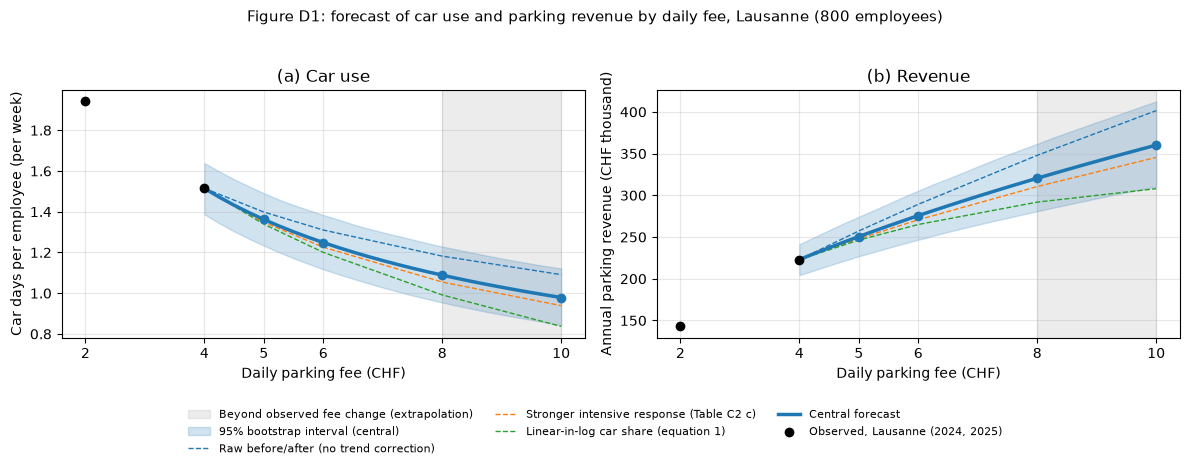

In [85]:
# Figure D1: central forecast (line), 95% bootstrap band, sensitivity scenarios (thin lines), observed points
grid = np.linspace(P0, 10, 25)
band = {"days": [], "rev": []}
for p in grid:
    r = p / P0
    s, d = sL25 * r ** e_ext, dL25 * r ** e_int
    band["days"].append(ci(s * d))
    band["rev"].append(ci(L25["n"] * s * d * WEEKS * p) / 1000)
band = {k: np.array(v) for k, v in band.items()}
cen = forecast(L25, P0, grid, eps_central["ext"], eps_central["int"])

obs_fee = [2, 4]
obs_days = [L24["share"] * L24["days_user"], L25["share"] * L25["days_user"]]
obs_rev = [L24["n"] * obs_days[0] * WEEKS * 2 / 1000, L25["n"] * obs_days[1] * WEEKS * 4 / 1000]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
panels = [("car_days_per_employee", 1, "days", obs_days, "Car days per employee (per week)", "(a) Car use"),
          ("revenue", 1 / 1000, "rev", obs_rev, "Annual parking revenue (CHF thousand)", "(b) Revenue")]
for ax, (col, scale, key, obs, ylabel, title) in zip(axes, panels):
    ax.axvspan(8, 10, color="grey", alpha=0.15, label="Beyond observed fee change (extrapolation)")
    ax.fill_between(grid, band[key][:, 0], band[key][:, 1], color="tab:blue", alpha=0.20, label="95% bootstrap interval (central)")
    for name, f in sens.items():
        if name.startswith("Central"):
            continue
        ax.plot(f.index, f[col] * scale, lw=1, ls="--", label=name)
    ax.plot(cen.index, cen[col] * scale, color="tab:blue", lw=2.5, label="Central forecast")
    ax.scatter(obs_fee, obs, color="black", zorder=5, label="Observed, Lausanne (2024, 2025)")
    for p in FEES:
        ax.scatter(p, central.loc[p, col] * scale, color="tab:blue", zorder=6)
    ax.set_xlabel("Daily parking fee (CHF)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks([2, 4, 5, 6, 8, 10])
    ax.grid(alpha=0.3)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=8, frameon=False)
fig.suptitle("Figure D1: forecast of car use and parking revenue by daily fee, Lausanne (800 employees)", fontsize=11)
fig.tight_layout(rect=[0, 0.14, 1, 0.95])
plt.show()

## D.4 Reading Figure D1 and limits of the forecast

**Figure D1.** Panel (a) shows the main behavioural outcome (car days per employee per week) and panel (b) the annual revenue, for fees between CHF 4 and CHF 10. Black dots are the observed Lausanne values at CHF 2 (2024) and CHF 4 (2025). The blue line is the central forecast with its 95% bootstrap interval, the dashed lines are the sensitivity scenarios of Table D1b, and the grey area (CHF 8 to 10) marks fees beyond the observed proportional change. The figure is saved as `figure_D1.png`.

**Assumptions, credible range and main risk.** The forecasts assume constant elasticities (extensive −0.374, intensive −0.102) from the observed CHF 4 baseline, the 2025 population, and a fee paid for every day driven. The credible range goes up to CHF 8, a further doubling, which is the same proportional change as the one observed; CHF 10 goes beyond it and is indicative only. The main reason forecasts may fail outside this range is that the elasticity is unlikely to stay constant: the employees who still drive at high fees have the fewest alternatives (see C.3 and Table B3), so the central forecast would overstate the decline in car use at CHF 8 and 10 and understate revenue.

In [86]:
# Extension to Sion (uniform tariff): the same central elasticities are APPLIED to Sion's 2025 baseline (CHF 2).
# Sion has never experienced a fee change, so this is a transfer assumption, and every fee above CHF 4
# is a larger proportional change than the one observed in Lausanne.
tariffs = [4, 5, 6, 8, 10]
sion = forecast(S25, 2, tariffs, eps_central["ext"], eps_central["int"])
sion["log_change_vs_observed"] = np.log(sion.index / 2) / np.log(2)

lau = forecast(L25, P0, tariffs, eps_central["ext"], eps_central["int"])

table_D2 = pd.DataFrame({
    "Sion car share (%)":                    sion["car_share"] * 100,
    "Sion days per car user":                sion["days_per_user"],
    "Sion car days per employee (per week)": sion["car_days_per_employee"],
    "Sion annual revenue (CHF)":             sion["revenue"],
    "Fee change vs observed (× ln 2)":       sion["log_change_vs_observed"],
    "Employer-wide revenue (CHF)":           sion["revenue"] + lau["revenue"],
})
print(f"Sion 2025 baseline at CHF 2: car share {S25['share']*100:.1f}%, {S25['days_user']:.2f} days per car user, "
      f"revenue CHF {S25['n'] * S25['share'] * S25['days_user'] * WEEKS * 2:,.0f}")
table_D2.round(2)

Sion 2025 baseline at CHF 2: car share 61.5%, 3.65 days per car user, revenue CHF 41,280


,Sion car share (%),Sion days per car user,Sion car days per employee (per week),Sion annual revenue (CHF),Fee change vs observed (× ln 2),Employer-wide revenue (CHF)
fee,,,,,,
4,47.44,3.40,1.61,59328.38,1.00,282317.98
5,43.64,3.32,1.45,66676.40,1.32,317284.02
6,40.76,3.26,1.33,73350.82,1.58,349044.67
8,36.60,3.17,1.16,85267.02,2.00,405748.69
10,33.67,3.09,1.04,95827.63,2.32,456002.04


## D.5 Extension to Sion (uniform tariff)

**Table D2: forecast for Sion and for the whole employer if the same tariff applied to both sites**

| Fee (CHF) | Sion car share | Sion days per car user | Sion car days per employee (per week) | Sion annual revenue (CHF) | Fee change vs observed (× ln 2) | Employer-wide revenue (CHF) |
|---|---:|---:|---:|---:|---:|---:|
| 2 (2025 baseline) | 61.5% | 3.65 | 2.24 | 41,280 | | |
| 4 | 47.4% | 3.40 | 1.61 | 59,328 | 1.00 | 282,318 |
| 5 | 43.6% | 3.32 | 1.45 | 66,676 | 1.32 | 317,284 |
| 6 | 40.8% | 3.26 | 1.33 | 73,351 | 1.58 | 349,045 |
| 8 | 36.6% | 3.17 | 1.16 | 85,267 | 2.00 | 405,749 |
| 10 | 33.7% | 3.09 | 1.04 | 95,828 | 2.32 | 456,002 |

*Employer-wide revenue = Lausanne (Table D1) + Sion, at the same tariff. For comparison, actual 2025 revenue is CHF 222,990 (Lausanne, CHF 4) + CHF 41,280 (Sion, CHF 2) = CHF 264,270.*

**Caveats specific to Sion.** (i) Sion has never had a fee change, so the Lausanne elasticities are transferred by assumption; the Sion population is small (200 employees) and the transit context differs (Part A). (ii) A move from CHF 2 to CHF 4 is exactly the observed change, but every higher tariff is a larger proportional change (up to 2.3 times the observed doubling at CHF 10), so only the CHF 4 row lies within the observed range. (iii) Group-level responses needed for Part E are not computed here; they are derived in Part E from the interaction models of B3 and C2.